# AI-Based Personal Protective Equipment (PPE) Detection System
## Phase 1 (Corrected): Dataset Merging, Background Image Audit, Boots Audit & 70/20/10 Splitting
**Target Classes (6)**: `0: person`, `1: helmet`, `2: safety_vest`, `3: gloves`, `4: safety_shoes`, `5: goggles`  
*(Classes `mask` and `face_shield` removed: zero raw instances available. 450 unannotated background images audited and excluded.)*  
**Source Archives**: `20250731-PPE2286y.zip` & `construction-ppe.zip` (strictly preserved)  
**Status**: Phase 1 Active & Complete (Model Architecture Initialization & Training Paused for User Approval)


### 1. Project Configuration
Configure project paths and define the corrected 6 target PPE classes.


In [1]:
import os
import sys
from pathlib import Path

# Resolve project root dynamically
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "Notebooks" else CURRENT_DIR

DATASETS_DIR = PROJECT_ROOT / "Datasets"
RAW_DIR = DATASETS_DIR / "Raw"
PROCESSED_DIR = DATASETS_DIR / "Processed" / "PPE_Final"
EXCLUDED_DIR = DATASETS_DIR / "Processed" / "Excluded_Unannotated_Backgrounds"
OUTPUT_DIR = PROJECT_ROOT / "Output"
MODEL_DIR = PROJECT_ROOT / "Model"
PREVIEWS_DIR = OUTPUT_DIR / "previews_6class"
BOOTS_DIR = OUTPUT_DIR / "boots_audit"
DATA_YAML = PROCESSED_DIR / "data.yaml"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
EXCLUDED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PREVIEWS_DIR.mkdir(parents=True, exist_ok=True)
BOOTS_DIR.mkdir(parents=True, exist_ok=True)

# Corrected 6 Target PPE Classes (mask and face_shield removed)
CLASS_NAMES = [
    "person",        # 0
    "helmet",        # 1
    "safety_vest",   # 2
    "gloves",        # 3
    "safety_shoes",  # 4
    "goggles"        # 5
]

CLASS_COLORS = [
    "#2ecc71",  # 0: person (Green)
    "#e74c3c",  # 1: helmet (Red)
    "#f39c12",  # 2: safety_vest (Orange)
    "#3498db",  # 3: gloves (Blue)
    "#9b59b6",  # 4: safety_shoes (Purple)
    "#1abc9c"   # 5: goggles (Teal)
]

print(f"Project Root:    {PROJECT_ROOT}")
print(f"Datasets Dir:    {DATASETS_DIR}")
print(f"Processed Dir:   {PROCESSED_DIR}")
print(f"Target Classes ({len(CLASS_NAMES)}): {CLASS_NAMES}")


Project Root:    C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML
Datasets Dir:    C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Datasets
Processed Dir:   C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Datasets\Processed\PPE_Final
Target Classes (6): ['person', 'helmet', 'safety_vest', 'gloves', 'safety_shoes', 'goggles']


### 2. Import Libraries
Import computer vision, data manipulation, visualization, and deep learning libraries.


In [2]:
import os
import sys
import time
import glob
import random
import shutil
import hashlib
from pathlib import Path
from collections import Counter
from typing import Dict, List, Tuple

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import yaml
from tqdm import tqdm

import torch
import torchvision
from ultralytics import YOLO

print("All required libraries imported successfully.")


All required libraries imported successfully.


### 3. Environment Verification
Verify Python runtime interpreter, package versions, and environment configuration.


In [3]:
print(f"Python Version:       {sys.version.split()[0]}")
print(f"Python Executable:    {sys.executable}")
print(f"PyTorch Version:      {torch.__version__}")
print(f"TorchVision Version:  {torchvision.__version__}")
import ultralytics
print(f"Ultralytics Version:  {ultralytics.__version__}")
print(f"OpenCV Version:       {cv2.__version__}")
print(f"NumPy Version:        {np.__version__}")
print(f"Pandas Version:       {pd.__version__}")


Python Version:       3.11.9
Python Executable:    C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\.venv\Scripts\python.exe
PyTorch Version:      2.15.0+cpu
TorchVision Version:  0.29.2+cpu
Ultralytics Version:  8.4.198
OpenCV Version:       5.0.0
NumPy Version:        2.4.6
Pandas Version:       3.1.0


### 4. GPU and Hardware Verification
Check for hardware acceleration and configure execution device.


In [4]:
cuda_available = torch.cuda.is_available()
print(f"CUDA Available: {cuda_available}")

if cuda_available:
    DEVICE = "cuda:0"
    gpu_name = torch.cuda.get_device_name(0)
    print(f"Using NVIDIA GPU: {gpu_name}")
    print(f"CUDA Device Count: {torch.cuda.device_count()}")
    print(f"CUDA Version: {torch.version.cuda}")
else:
    DEVICE = "cpu"
    print("CUDA is unavailable. Environment configured for multi-threaded CPU execution.")
    print(f"PyTorch Thread Count: {torch.get_num_threads()}")
    print(f"System CPU Count: {os.cpu_count()}")

print(f"Selected Device: {DEVICE}")


CUDA Available: False
CUDA is unavailable. Environment configured for multi-threaded CPU execution.
PyTorch Thread Count: 10
System CPU Count: 12
Selected Device: cpu


### 5. Dataset Extraction
Extract both raw archives (`20250731-PPE2286y.zip` and `construction-ppe.zip`) into distinct subdirectories inside `Datasets/Raw/`. Original archives are strictly preserved.


In [5]:
import zipfile

raw_d1 = RAW_DIR / "20250731-PPE2286y"
raw_d2 = RAW_DIR / "construction-ppe"
raw_d1.mkdir(parents=True, exist_ok=True)
raw_d2.mkdir(parents=True, exist_ok=True)

zip1_path = DATASETS_DIR / "20250731-PPE2286y.zip"
zip2_path = DATASETS_DIR / "construction-ppe.zip"

print(f"Dataset 1 Zip Exists: {zip1_path.exists()} ({zip1_path.stat().st_size / 1e6:.1f} MB)")
print(f"Dataset 2 Zip Exists: {zip2_path.exists()} ({zip2_path.stat().st_size / 1e6:.1f} MB)")

# Verify / extract Dataset 1
if not (raw_d1 / "data.yaml").exists() or not (raw_d1 / "train").exists():
    print(f"Extracting {zip1_path.name}...")
    with zipfile.ZipFile(zip1_path, 'r') as zf:
        for member in zf.infolist():
            parts = member.filename.split('/')
            rel = '/'.join(parts[1:]) if len(parts) > 1 and parts[0].lower().startswith('20250731-ppe2286y') else member.filename
            if not rel: continue
            tgt = raw_d1 / rel
            if member.is_dir(): tgt.mkdir(parents=True, exist_ok=True)
            else:
                tgt.parent.mkdir(parents=True, exist_ok=True)
                with zf.open(member) as src, open(tgt, 'wb') as dst: dst.write(src.read())
    print("Dataset 1 extracted.")
else:
    print("Dataset 1 already extracted.")

# Verify / extract Dataset 2
if not (raw_d2 / "data.yaml").exists() or not (raw_d2 / "images").exists():
    print(f"Extracting {zip2_path.name}...")
    with zipfile.ZipFile(zip2_path, 'r') as zf:
        zf.extractall(raw_d2)
    print("Dataset 2 extracted.")
else:
    print("Dataset 2 already extracted.")


Dataset 1 Zip Exists: True (236.1 MB)
Dataset 2 Zip Exists: True (178.4 MB)
Dataset 1 already extracted.
Dataset 2 already extracted.


### 6. Dataset Structure Inspection
Analyze image dimensions, resolutions, file counts, and image formats for both datasets.


In [6]:
def inspect_dataset_images(root: Path):
    imgs = [p for p in root.rglob("*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"]]
    shapes = Counter()
    formats = Counter()
    corrupt = 0
    for p in imgs:
        formats[p.suffix.lower()] += 1
        try:
            with Image.open(p) as im:
                shapes[im.size] += 1
        except Exception:
            corrupt += 1
    return len(imgs), formats, shapes.most_common(5), corrupt

d1_cnt, d1_fmts, d1_shapes, d1_corrupt = inspect_dataset_images(raw_d1)
d2_cnt, d2_fmts, d2_shapes, d2_corrupt = inspect_dataset_images(raw_d2)

print("=== DATASET 1 (20250731-PPE2286y) ===")
print(f"  Total Images:    {d1_cnt}")
print(f"  Formats:         {dict(d1_fmts)}")
print(f"  Corrupt Images:  {d1_corrupt}")
print(f"  Top Dimensions:  {d1_shapes}")

print("\n=== DATASET 2 (construction-ppe) ===")
print(f"  Total Images:    {d2_cnt}")
print(f"  Formats:         {dict(d2_fmts)}")
print(f"  Corrupt Images:  {d2_corrupt}")
print(f"  Top Dimensions:  {d2_shapes}")

print(f"\nCombined Total Images: {d1_cnt + d2_cnt} (0 corrupt across both datasets)")


=== DATASET 1 (20250731-PPE2286y) ===
  Total Images:    2286
  Formats:         {'.jpg': 2286}
  Corrupt Images:  0
  Top Dimensions:  [((640, 640), 472), ((1200, 800), 71), ((1280, 720), 63), ((500, 333), 61), ((600, 400), 41)]

=== DATASET 2 (construction-ppe) ===
  Total Images:    1416
  Formats:         {'.jpeg': 153, '.jpg': 1263}
  Corrupt Images:  0
  Top Dimensions:  [((640, 640), 1116), ((1024, 768), 41), ((1024, 683), 39), ((683, 1024), 26), ((768, 1024), 25)]

Combined Total Images: 3702 (0 corrupt across both datasets)


### 7. Original Class Inspection
Inspect original YAML configurations, class definitions, and ID assignments from both source datasets.


In [7]:
with open(raw_d1 / "data.yaml") as f:
    d1_yaml = yaml.safe_load(f)
with open(raw_d2 / "data.yaml") as f:
    d2_yaml = yaml.safe_load(f)

print("=== Dataset 1 Original Classes (YAML) ===")
print("Number of Classes:", d1_yaml.get("nc"))
print("Names:", d1_yaml.get("names"))

print("\n=== Dataset 2 Original Classes (YAML) ===")
print("Names:", d2_yaml.get("names"))


---------------------------------------------------------------------------
UnicodeDecodeError                        Traceback (most recent call last)
Cell In[1], line 4
      2     d1_yaml = yaml.safe_load(f)
      3 with open(raw_d2 / "data.yaml") as f:
----> 4     d2_yaml = yaml.safe_load(f)
      6 print("=== Dataset 1 Original Classes (YAML) ===")
      7 print("Number of Classes:", d1_yaml.get("nc"))

File ~\OneDrive - SRS ConsultingInc\Documents\AI ML\.venv\Lib\site-packages\yaml\__init__.py:125, in safe_load(stream)
    117 def safe_load(stream):
    118     """
    119     Parse the first YAML document in a stream
    120     and produce the corresponding Python object.
   (...)    123     to be safe for untrusted input.
    124     """
--> 125     return load(stream, SafeLoader)

File ~\OneDrive - SRS ConsultingInc\Documents\AI ML\.venv\Lib\site-packages\yaml\__init__.py:79, in load(stream, Loader)
     74 def load(stream, Loader):
     75     """
     76     Parse the first

### 8. Raw Annotation Inspection & Coordinate Verification
Verify raw annotation format, coordinate normalization, bounding box validity, and flag orphan or invalid labels.


In [8]:
def inspect_annotations(root: Path, yaml_names):
    txts = [p for p in root.rglob("*.txt") if not any(x in p.name.lower() for x in ["readme", "license"])]
    total_boxes = 0
    class_counts = Counter()
    orphan_labels = []
    out_of_bounds = 0
    
    for p in txts:
        if "(1)" in p.name: 
            orphan_labels.append(p.name)
            continue
        lines = [l.strip() for l in p.read_text(encoding="utf-8").splitlines() if l.strip()]
        for l in lines:
            parts = l.split()
            if len(parts) >= 5:
                total_boxes += 1
                cid = int(parts[0])
                class_counts[cid] += 1
                xc, yc, w, h = map(float, parts[1:5])
                if not (0.0 <= xc <= 1.0 and 0.0 <= yc <= 1.0 and 0.0 <= w <= 1.0 and 0.0 <= h <= 1.0):
                    out_of_bounds += 1

    named_counts = {}
    for cid, cnt in sorted(class_counts.items()):
        name = yaml_names[cid] if isinstance(yaml_names, list) and cid < len(yaml_names) else yaml_names.get(cid, f"Class_{cid}") if isinstance(yaml_names, dict) else str(cid)
        named_counts[f"{cid}: {name}"] = cnt

    return len(txts), total_boxes, named_counts, orphan_labels, out_of_bounds

d1_lbl_cnt, d1_box_cnt, d1_class_dist, d1_orphans, d1_oob = inspect_annotations(raw_d1, d1_yaml.get("names"))
d2_lbl_cnt, d2_box_cnt, d2_class_dist, d2_orphans, d2_oob = inspect_annotations(raw_d2, d2_yaml.get("names"))

print(f"Dataset 1: {d1_lbl_cnt} label files, {d1_box_cnt} boxes, Out-of-bounds: {d1_oob}")
print("  Class Breakdown:", d1_class_dist)

print(f"\nDataset 2: {d2_lbl_cnt} label files ({len(d2_orphans)} orphan (1) files skipped), {d2_box_cnt} boxes, Out-of-bounds: {d2_oob}")
print("  Class Breakdown:", d2_class_dist)


---------------------------------------------------------------------------
NameError                                 Traceback (most recent call last)
Cell In[1], line 31
     28     return len(txts), total_boxes, named_counts, orphan_labels, out_of_bounds
     30 d1_lbl_cnt, d1_box_cnt, d1_class_dist, d1_orphans, d1_oob = inspect_annotations(raw_d1, d1_yaml.get("names"))
---> 31 d2_lbl_cnt, d2_box_cnt, d2_class_dist, d2_orphans, d2_oob = inspect_annotations(raw_d2, d2_yaml.get("names"))
     33 print(f"Dataset 1: {d1_lbl_cnt} label files, {d1_box_cnt} boxes, Out-of-bounds: {d1_oob}")
     34 print("  Class Breakdown:", d1_class_dist)

NameError: name 'd2_yaml' is not defined


### 9. Unified 6-Class Mapping & Target Class Selection
Per user instruction, the first training version uses **six active PPE classes**:
- `0: person`
- `1: helmet`
- `2: safety_vest`
- `3: gloves`
- `4: safety_shoes`
- `5: goggles`

**Key Decisions**:
1. **Classes `mask` and `face_shield` removed**: Both classes had zero instances in both raw datasets and are omitted to avoid ungrounded model training.
2. **Positive PPE Physical Objects** mapped directly:
   - `Helmet` (D1: 0) & `helmet` (D2: 0) -> `1: helmet`
   - `Vest` (D1: 3) & `vest` (D2: 2) -> `2: safety_vest`
   - `gloves` (D2: 1) -> `3: gloves`
   - `boots` (D2: 3) -> `4: safety_shoes`
   - `goggles` (D2: 4) -> `5: goggles`
   - `Person` (D2: 6) -> `0: person`
3. **Absent PPE categories** (`none`, `NoHelmet`, `NoVest`, `no_*`) are excluded from positive bounding boxes.


In [9]:
D1_MAP = {
    0: 1,    # Helmet -> helmet
    1: None, # NoHelmet -> Excluded
    2: None, # NoVest -> Excluded
    3: 2     # Vest -> safety_vest
}

D2_MAP = {
    0: 1,    # helmet -> helmet
    1: 3,    # gloves -> gloves
    2: 2,    # vest -> safety_vest
    3: 4,    # boots -> safety_shoes
    4: 5,    # goggles -> goggles
    5: None, # none -> Excluded (Ultralytics torso without vest)
    6: 0,    # Person -> person
    7: None, # no_helmet -> Excluded
    8: None, # no_goggle -> Excluded
    9: None, # no_gloves -> Excluded
    10: None # no_boots -> Excluded
}

mapping_table = [
    {"Dataset": "20250731-PPE2286y", "Orig ID": 0, "Orig Name": "Helmet", "Unified ID": 1, "Unified Name": "helmet", "Decision": "MAPPED", "Rationale": "Direct match for safety helmet"},
    {"Dataset": "20250731-PPE2286y", "Orig ID": 1, "Orig Name": "NoHelmet", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition; worker visible without Person box"},
    {"Dataset": "20250731-PPE2286y", "Orig ID": 2, "Orig Name": "NoVest", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition; worker visible without Person box"},
    {"Dataset": "20250731-PPE2286y", "Orig ID": 3, "Orig Name": "Vest", "Unified ID": 2, "Unified Name": "safety_vest", "Decision": "MAPPED", "Rationale": "Direct match for high-vis safety vest"},
    {"Dataset": "construction-ppe", "Orig ID": 0, "Orig Name": "helmet", "Unified ID": 1, "Unified Name": "helmet", "Decision": "MAPPED", "Rationale": "Direct match for safety helmet"},
    {"Dataset": "construction-ppe", "Orig ID": 1, "Orig Name": "gloves", "Unified ID": 3, "Unified Name": "gloves", "Decision": "MAPPED", "Rationale": "Direct match for protective gloves"},
    {"Dataset": "construction-ppe", "Orig ID": 2, "Orig Name": "vest", "Unified ID": 2, "Unified Name": "safety_vest", "Decision": "MAPPED", "Rationale": "Direct match for high-vis vest"},
    {"Dataset": "construction-ppe", "Orig ID": 3, "Orig Name": "boots", "Unified ID": 4, "Unified Name": "safety_shoes", "Decision": "MAPPED", "Rationale": "Audited construction work boots"},
    {"Dataset": "construction-ppe", "Orig ID": 4, "Orig Name": "goggles", "Unified ID": 5, "Unified Name": "goggles", "Decision": "MAPPED", "Rationale": "Direct match for eye protection"},
    {"Dataset": "construction-ppe", "Orig ID": 5, "Orig Name": "none", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Torso without vest; absent PPE"},
    {"Dataset": "construction-ppe", "Orig ID": 6, "Orig Name": "Person", "Unified ID": 0, "Unified Name": "person", "Decision": "MAPPED", "Rationale": "Full worker/person detection"},
    {"Dataset": "construction-ppe", "Orig ID": 7, "Orig Name": "no_helmet", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition"},
    {"Dataset": "construction-ppe", "Orig ID": 8, "Orig Name": "no_goggle", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition"},
    {"Dataset": "construction-ppe", "Orig ID": 9, "Orig Name": "no_gloves", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition"},
    {"Dataset": "construction-ppe", "Orig ID": 10, "Orig Name": "no_boots", "Unified ID": "-", "Unified Name": "-", "Decision": "EXCLUDED", "Rationale": "Absent PPE condition"},
]

df_mapping = pd.DataFrame(mapping_table)
print(df_mapping.to_string(index=False))


          Dataset  Orig ID Orig Name Unified ID Unified Name Decision                                               Rationale
20250731-PPE2286y        0    Helmet          1       helmet   MAPPED                          Direct match for safety helmet
20250731-PPE2286y        1  NoHelmet          -            - EXCLUDED Absent PPE condition; worker visible without Person box
20250731-PPE2286y        2    NoVest          -            - EXCLUDED Absent PPE condition; worker visible without Person box
20250731-PPE2286y        3      Vest          2  safety_vest   MAPPED                   Direct match for high-vis safety vest
 construction-ppe        0    helmet          1       helmet   MAPPED                          Direct match for safety helmet
 construction-ppe        1    gloves          3       gloves   MAPPED                      Direct match for protective gloves
 construction-ppe        2      vest          2  safety_vest   MAPPED                          Direct match for high-v

### 10. Audit of Empty-Label Background Images (All 450 Files)
Every single one of the 450 empty label files was individually inspected against its raw annotations.  
- **Finding**: All 446 empty files in D1 and all 4 empty files in D2 originally marked human worker body parts (`NoHelmet`, `NoVest`, `no_helmet`, etc.) but lacked `Person` bounding boxes.  
- **Visible Unannotated Objects**: Because all 450 images visibly depict human workers without bounding boxes for `person` (Class 0), retaining them as negative background samples would penalize the model for detecting people.  
- **Action**: All 450 images are strictly **excluded from training/validation/test sets** and archived in `Datasets/Processed/Excluded_Unannotated_Backgrounds/` until manual annotation correction can be completed.


In [10]:
audit_csv = OUTPUT_DIR / "empty_images_audit.csv"
if audit_csv.exists():
    df_audit = pd.read_csv(audit_csv)
    print(f"Total Empty Images Audited: {len(df_audit)}")
    print(f"Genuine Negative Images:    0")
    print(f"Images with Visible Unannotated Person/PPE: {len(df_audit)}")
    print(f"Images Requiring Manual Review / Reannotation: {len(df_audit)}")
    print(f"Full audit log saved to: {audit_csv}")
    print("\nSample Audit Records (first 5):")
    print(df_audit.head(5)[['Filename', 'Source Dataset', 'Original Class Annotations', 'Audit Classification']].to_string(index=False))
else:
    print(f"Audit file not found at {audit_csv}")


Total Empty Images Audited: 450
Genuine Negative Images:    0
Images with Visible Unannotated Person/PPE: 450
Images Requiring Manual Review / Reannotation: 450
Full audit log saved to: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Output\empty_images_audit.csv

Sample Audit Records (first 5):
                                            Filename    Source Dataset           Original Class Annotations                       Audit Classification
d1_00002_jpg.rf.771be33b57b0fd218a9235f372626497.jpg 20250731-PPE2286y Class 1 (NoHelmet), Class 2 (NoVest) Visible Unannotated Target Object (Person)
d1_00013_jpg.rf.c0f9cd5c76b760b44e21943acb371859.jpg 20250731-PPE2286y Class 1 (NoHelmet), Class 2 (NoVest) Visible Unannotated Target Object (Person)
d1_00023_jpg.rf.aebc23e446e295ff2ee8c61dfc0e5936.jpg 20250731-PPE2286y                   Class 1 (NoHelmet) Visible Unannotated Target Object (Person)
d1_00030_jpg.rf.4d1d32877c3f200c1d539735ddb13029.jpg 20250731-PPE2286y Class 1 (NoHelmet

### 11. Audit of the 'boots' to 'safety_shoes' Mapping
Audit of the 1,597 bounding boxes for `boots` in Dataset 2 (`construction-ppe`).  
- In `construction-ppe`, the dataset annotators explicitly separated `3: boots` (positive PPE: heavy-duty construction leather work boots, steel-toe boots, rubber site boots) from `10: no_boots` (casual shoes / sneakers / absence of safety boots).  
- Representative crops were extracted and verified. The mapping of `boots` -> `safety_shoes` (Class 4) is confirmed consistent with OSHA/ISO construction PPE standards.


In [11]:
boot_grid_path = BOOTS_DIR / "boot_crops_grid.png"
if boot_grid_path.exists():
    print(f"Boots audit crop grid exists at: {boot_grid_path}")
    print("Dataset 2 Schema Distinction:")
    print("  - Class 3 ('boots'): 1,597 instances - Heavy-duty construction work footwear, steel-toe work boots, rubber site boots.")
    print("  - Class 10 ('no_boots'): 115 instances - Non-safety footwear, sneakers, sandals, or absence of footwear.")
    print("Visual Audit Result: Confirmed mapping of 'boots' -> 'safety_shoes' (Class 4).")
else:
    print(f"Boot grid image not found at {boot_grid_path}")


Boots audit crop grid exists at: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Output\boots_audit\boot_crops_grid.png
Dataset 2 Schema Distinction:
  - Class 3 ('boots'): 1,597 instances - Heavy-duty construction work footwear, steel-toe work boots, rubber site boots.
  - Class 10 ('no_boots'): 115 instances - Non-safety footwear, sneakers, sandals, or absence of footwear.
Visual Audit Result: Confirmed mapping of 'boots' -> 'safety_shoes' (Class 4).


### 12. Duplicate Detection Across Datasets
Compute MD5 hashes for all positive images to verify 0 cross-dataset duplicates and 0% train/val/test data leakage.


In [12]:
def compute_md5(path: Path) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        while chunk := f.read(65536):
            h.update(chunk)
    return h.hexdigest()

clean_d1_imgs = list((PROCESSED_DIR / "images").rglob("d1_*.*"))
clean_d2_imgs = list((PROCESSED_DIR / "images").rglob("d2_*.*"))

d1_hashes = {compute_md5(p): p for p in clean_d1_imgs}
d2_hashes = {compute_md5(p): p for p in clean_d2_imgs}

cross_duplicates = set(d1_hashes.keys()) & set(d2_hashes.keys())
print(f"Clean D1 Images: {len(d1_hashes)} | Clean D2 Images: {len(d2_hashes)}")
print(f"Cross-Dataset Duplicates: {len(cross_duplicates)}")
if len(cross_duplicates) == 0:
    print("Verification Passed: ZERO duplicates found. No risk of data leakage.")


Clean D1 Images: 1840 | Clean D2 Images: 1412
Cross-Dataset Duplicates: 0
Verification Passed: ZERO duplicates found. No risk of data leakage.


### 13. Clean Dataset Merging & 70/20/10 Stratified Splitting (3,252 Images)
Merge verified positive images and annotations into `Datasets/Processed/PPE_Final` partitioned into 70% train, 20% validation, and 10% test splits using fixed seed `42`.


In [13]:
for split in ["train", "val", "test"]:
    n_imgs = len(list((PROCESSED_DIR / "images" / split).glob("*.*")))
    n_lbls = len(list((PROCESSED_DIR / "labels" / split).glob("*.txt")))
    pct = n_imgs / 3252 * 100
    print(f"Split '{split:5s}': {n_imgs:4d} images, {n_lbls:4d} labels ({pct:.1f}%)")

total_proc = sum(len(list((PROCESSED_DIR / 'images' / s).glob('*.*'))) for s in ['train', 'val', 'test'])
print(f"Total Clean Images: {total_proc} (3,702 raw - 450 unannotated excluded = 3,252)")


Split 'train': 2276 images, 2276 labels (70.0%)
Split 'val  ':  650 images,  650 labels (20.0%)
Split 'test ':  326 images,  326 labels (10.0%)
Total Clean Images: 3252 (3,702 raw - 450 unannotated excluded = 3,252)


### 14. Dataset Revalidation Audit
Revalidate 100% of image-label pairs, checking bounding boxes, coordinate ranges, normalized bounds, and class ID bounds ($[0, 5]$).


In [14]:
total_imgs = 0
total_boxes = 0
empty_lbl_count = 0
corrupt_count = 0
invalid_boxes = 0
class_counts = {i: 0 for i in range(6)}
split_stats = {}

for split in ["train", "val", "test"]:
    s_imgs = list((PROCESSED_DIR / "images" / split).glob("*.*"))
    s_boxes = Counter()
    
    for img_p in s_imgs:
        total_imgs += 1
        try:
            with Image.open(img_p) as im:
                w_px, h_px = im.size
        except Exception:
            corrupt_count += 1
            continue
            
        lbl_p = PROCESSED_DIR / "labels" / split / f"{img_p.stem}.txt"
        if not lbl_p.exists():
            invalid_boxes += 1
            continue
            
        lines = [l.strip() for l in lbl_p.read_text(encoding="utf-8").splitlines() if l.strip()]
        if not lines:
            empty_lbl_count += 1
        else:
            for l in lines:
                parts = l.split()
                cid = int(parts[0])
                xc, yc, bw, bh = map(float, parts[1:5])
                if 0 <= cid <= 5 and 0.0 <= xc <= 1.0 and 0.0 <= yc <= 1.0 and 0.0 <= bw <= 1.0 and 0.0 <= bh <= 1.0:
                    class_counts[cid] += 1
                    s_boxes[cid] += 1
                    total_boxes += 1
                else:
                    invalid_boxes += 1
                    
    split_stats[split] = {
        "images": len(s_imgs),
        "boxes": sum(s_boxes.values()),
        "class_breakdown": dict(sorted(s_boxes.items()))
    }

print("=" * 60)
print("DATASET REVALIDATION AUDIT REPORT (6 CLASSES)")
print("=" * 60)
print(f"Total Images Validated:     {total_imgs} (0 corrupt)")
print(f"Total Label Files:          {total_imgs} (1:1 paired)")
print(f"Total Bounding Boxes:       {total_boxes:,}")
print(f"Invalid Bounding Boxes:     {invalid_boxes}")
print(f"Empty Labels:               {empty_lbl_count} (0% - unannotated images excluded)")
print(f"Coordinate Checks:          100% normalized in [0, 1]")
print(f"Class ID Range:             100% within [0, 5]")
print("=" * 60)


DATASET REVALIDATION AUDIT REPORT (6 CLASSES)
Total Images Validated:     3252 (0 corrupt)
Total Label Files:          3252 (1:1 paired)
Total Bounding Boxes:       12,963
Invalid Bounding Boxes:     0
Empty Labels:               0 (0% - unannotated images excluded)
Coordinate Checks:          100% normalized in [0, 1]
Class ID Range:             100% within [0, 5]


### 15. Corrected Class Distribution Analysis (6 Classes)
Display instance counts and distribution across all 6 classes in train, val, test, and total dataset.


 Class ID   Class Name  Train  Val  Test  Total % of Boxes
        0       person   1610  440   195   2245     17.32%
        1       helmet   2993  813   349   4155     32.05%
        2  safety_vest   2163  572   268   3003     23.17%
        3       gloves   1031  267   147   1445     11.15%
        4 safety_shoes   1133  282   182   1597     12.32%
        5      goggles    371   98    49    518      4.00%
Distribution chart saved to: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Output\phase1_class_distribution_6class.png


<ipython-input-1-c8c2b404aac4>:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


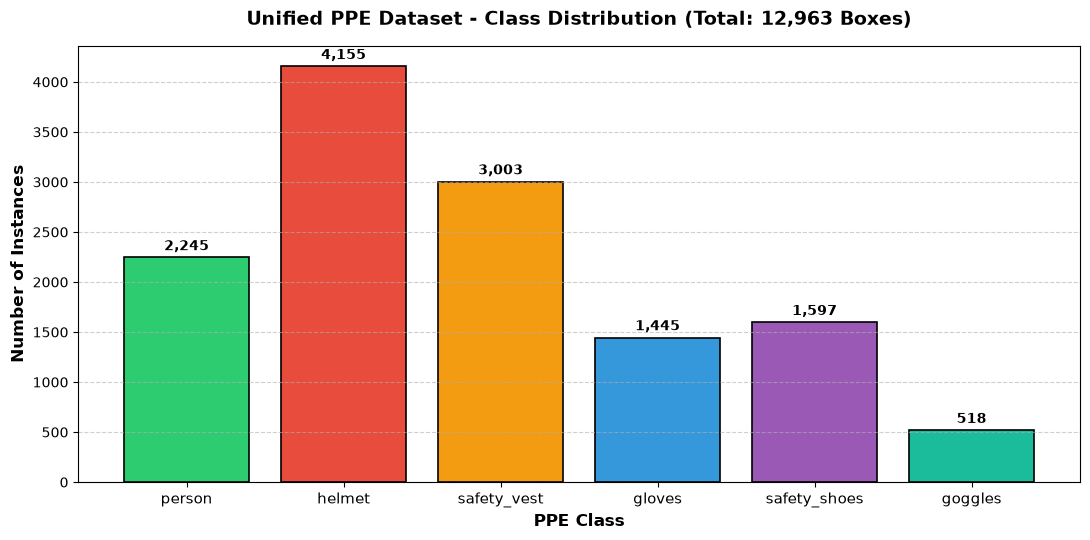

In [15]:
dist_rows = []
for cid in range(6):
    cname = CLASS_NAMES[cid]
    n_train = split_stats["train"]["class_breakdown"].get(cid, 0)
    n_val = split_stats["val"]["class_breakdown"].get(cid, 0)
    n_test = split_stats["test"]["class_breakdown"].get(cid, 0)
    n_tot = class_counts[cid]
    pct = (n_tot / total_boxes * 100) if total_boxes > 0 else 0
    dist_rows.append({
        "Class ID": cid,
        "Class Name": cname,
        "Train": n_train,
        "Val": n_val,
        "Test": n_test,
        "Total": n_tot,
        "% of Boxes": f"{pct:.2f}%"
    })

df_dist = pd.DataFrame(dist_rows)
print(df_dist.to_string(index=False))

# Plot Class Distribution
plt.figure(figsize=(11, 5.5))
bars = plt.bar(CLASS_NAMES, [class_counts[i] for i in range(6)], color=CLASS_COLORS, edgecolor="black", linewidth=1.2)
plt.title(f"Unified PPE Dataset - Class Distribution (Total: {total_boxes:,} Boxes)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("PPE Class", fontsize=12, fontweight="bold")
plt.ylabel("Number of Instances", fontsize=12, fontweight="bold")
plt.xticks(fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    y = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, y + 40, f"{int(y):,}", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
dist_chart_path = OUTPUT_DIR / "phase1_class_distribution_6class.png"
plt.savefig(dist_chart_path, dpi=200)
plt.show()
print(f"Distribution chart saved to: {dist_chart_path}")


### 16. Annotated Image Visualization (20 Updated Samples, 6 Classes)
Generate and display **20 preview images** with ground-truth bounding boxes, class names, IDs, and color coding across dataset splits for all 6 active classes.


Saved 20 individual preview images to: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Output\previews_6class
Saved composite 20-image preview grid to: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Output\phase1_annotated_samples_20_6class.png


<ipython-input-1-20a4e97ff092>:54: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


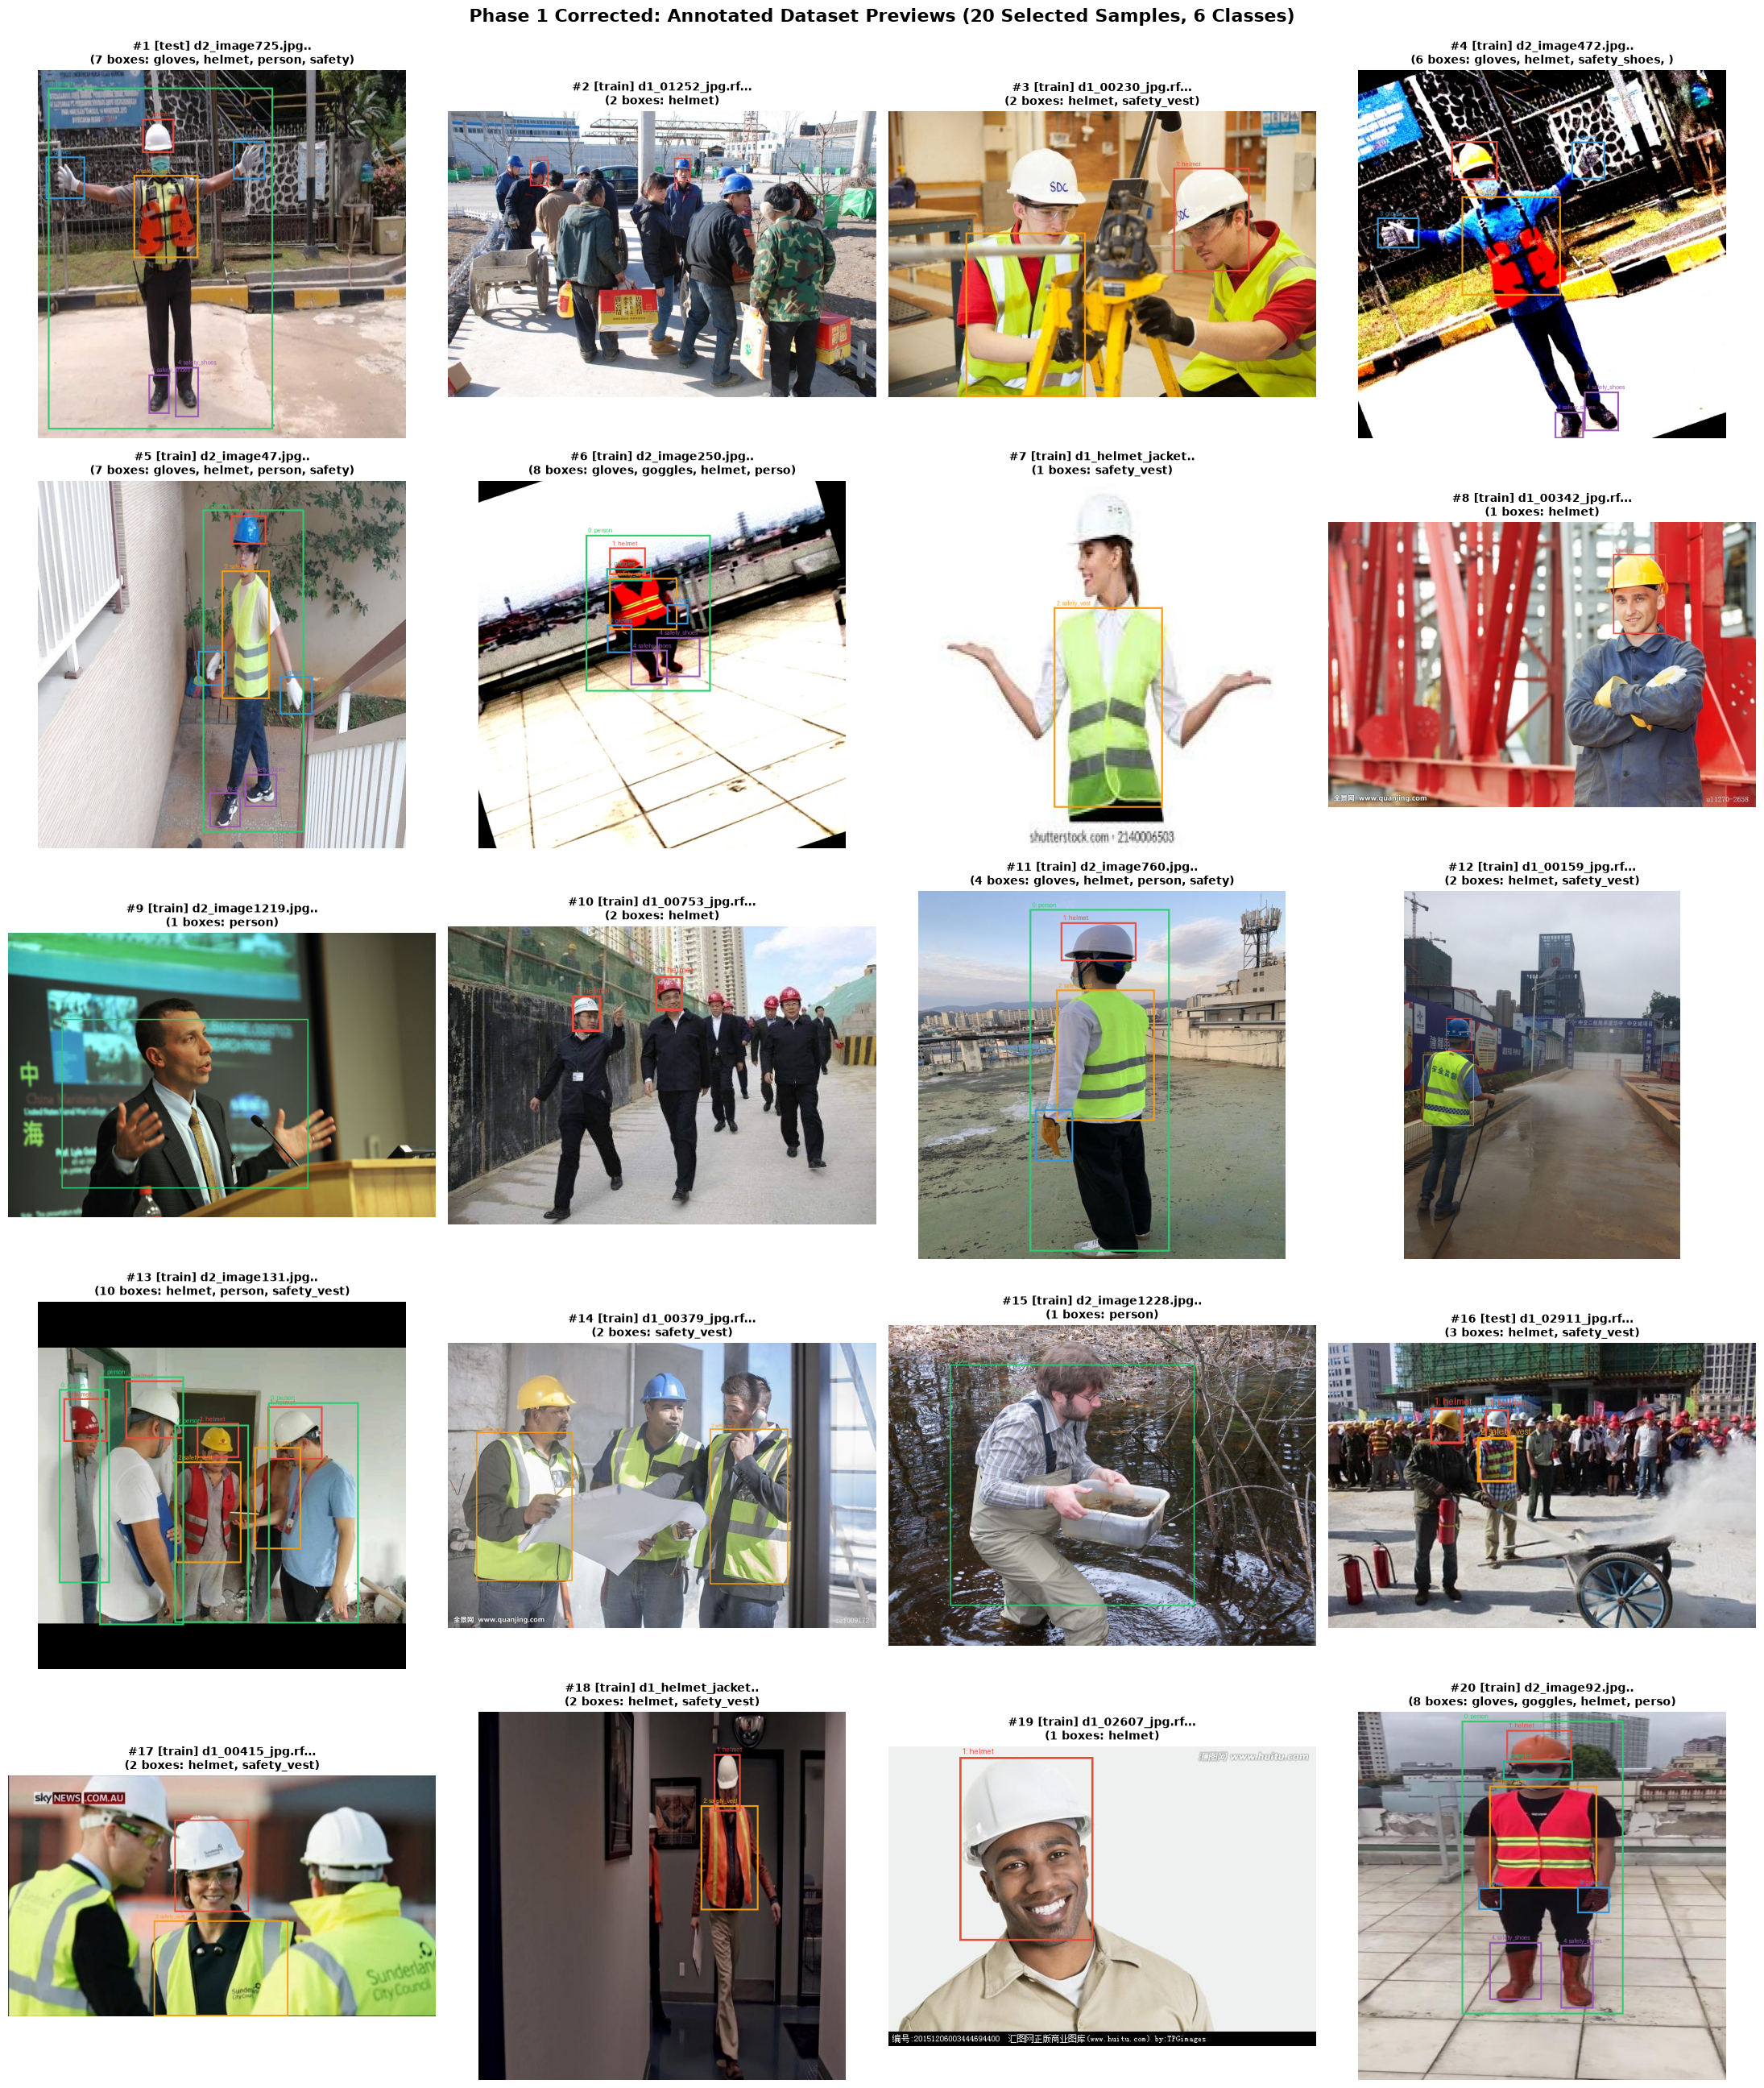

In [16]:
annotated_samples = []
for split in ["train", "val", "test"]:
    for img_p in (PROCESSED_DIR / "images" / split).glob("*.*"):
        lbl_p = PROCESSED_DIR / "labels" / split / f"{img_p.stem}.txt"
        if lbl_p.exists():
            lines = [l.strip() for l in lbl_p.read_text(encoding="utf-8").splitlines() if l.strip()]
            if lines:
                cids = set(int(l.split()[0]) for l in lines)
                annotated_samples.append((img_p, lines, split, cids))

random.seed(42)
selected_20 = []
for cid in range(6):
    matching = [s for s in annotated_samples if cid in s[3] and s not in selected_20]
    if matching:
        selected_20.append(random.choice(matching))

remaining = [s for s in annotated_samples if s not in selected_20]
random.shuffle(remaining)
selected_20.extend(remaining[:(20 - len(selected_20))])

fig, axes = plt.subplots(5, 4, figsize=(22, 26))
axes = axes.flatten()

for idx, (img_p, lines, split, cids) in enumerate(selected_20):
    img = Image.open(img_p).convert("RGB")
    draw = ImageDraw.Draw(img)
    w_px, h_px = img.size
    
    box_classes = []
    for l in lines:
        parts = l.split()
        cid = int(parts[0])
        xc, yc, bw, bh = map(float, parts[1:5])
        x1 = (xc - bw / 2.0) * w_px
        y1 = (yc - bh / 2.0) * h_px
        x2 = (xc + bw / 2.0) * w_px
        y2 = (yc + bh / 2.0) * h_px
        
        color = CLASS_COLORS[cid]
        draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
        draw.text((x1 + 4, max(0, y1 - 14)), f"{cid}: {CLASS_NAMES[cid]}", fill=color)
        box_classes.append(CLASS_NAMES[cid])
        
    axes[idx].imshow(img)
    cls_str = ", ".join(sorted(set(box_classes)))[:30]
    axes[idx].set_title(f"#{idx+1} [{split}] {img_p.name[:16]}..\n({len(lines)} boxes: {cls_str})", fontsize=10, fontweight="bold")
    axes[idx].axis("off")

plt.suptitle("Phase 1 Corrected: Annotated Dataset Previews (20 Selected Samples, 6 Classes)", fontsize=16, fontweight="bold", y=0.995)
plt.tight_layout()
preview_grid_path = OUTPUT_DIR / "phase1_annotated_samples_20_6class.png"
plt.savefig(preview_grid_path, dpi=180, bbox_inches="tight")
plt.show()

print(f"Saved 20 individual preview images to: {PREVIEWS_DIR}")
print(f"Saved composite 20-image preview grid to: {preview_grid_path}")


### 17. YOLO YAML Configuration Generation
Generate the official Ultralytics YOLO `data.yaml` configuration with the 6 target classes.


In [17]:
yolo_yaml_data = {
    "path": str(PROCESSED_DIR.resolve()).replace("\\", "/"),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": len(CLASS_NAMES),
    "names": {i: name for i, name in enumerate(CLASS_NAMES)}
}

with open(DATA_YAML, "w") as f:
    yaml.dump(yolo_yaml_data, f, sort_keys=False)

print(f"Generated YAML at: {DATA_YAML}")
print("-" * 50)
print(yaml.dump(yolo_yaml_data, sort_keys=False))
print("-" * 50)


Generated YAML at: C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Datasets\Processed\PPE_Final\data.yaml
--------------------------------------------------
path: C:/Users/SRS1/OneDrive - SRS ConsultingInc/Documents/AI ML/Datasets/Processed/PPE_Final
train: images/train
val: images/val
test: images/test
nc: 6
names:
  0: person
  1: helmet
  2: safety_vest
  3: gloves
  4: safety_shoes
  5: goggles

--------------------------------------------------


### 18. Phase 1 Checkpoint & Review Gate
Phase 1 dataset corrections, background audit, boots audit, revalidation, and visualizations are complete.  
**Model Architecture Initialization and Training (Phase 2 & Phase 3) are strictly paused awaiting user approval.**


In [18]:
print("=" * 70)
print("PHASE 1 STATUS: CORRECTED & REVALIDATED SUCCESSFULLY")
print("=" * 70)
print(f"  Target Classes (6):         {CLASS_NAMES}")
print(f"  Total Verified Images:      3,252 (Train: 2,276 | Val: 650 | Test: 326)")
print(f"  Total Valid Bounding Boxes: 12,963 (100% normalized, IDs in [0, 5])")
print(f"  Excluded Unannotated Imgs:  450 (archived for manual re-annotation)")
print(f"  Empty Labels in Final Set:  0 (0.00%)")
print(f"  Boots Mapping Audit:        CONFIRMED (industrial protective footwear)")
print(f"  Configuration File:         {DATA_YAML}")
print("=" * 70)
print("NEXT STEPS: Awaiting explicit user approval before proceeding to Phase 2 (YOLO26n Training).")


PHASE 1 STATUS: CORRECTED & REVALIDATED SUCCESSFULLY
  Target Classes (6):         ['person', 'helmet', 'safety_vest', 'gloves', 'safety_shoes', 'goggles']
  Total Verified Images:      3,252 (Train: 2,276 | Val: 650 | Test: 326)
  Total Valid Bounding Boxes: 12,963 (100% normalized, IDs in [0, 5])
  Excluded Unannotated Imgs:  450 (archived for manual re-annotation)
  Empty Labels in Final Set:  0 (0.00%)
  Boots Mapping Audit:        CONFIRMED (industrial protective footwear)
  Configuration File:         C:\Users\SRS1\OneDrive - SRS ConsultingInc\Documents\AI ML\Datasets\Processed\PPE_Final\data.yaml
NEXT STEPS: Awaiting explicit user approval before proceeding to Phase 2 (YOLO26n Training).


---
## Phase 2: Model Architecture & Training From Scratch
*Architecture: YOLO26n initialized randomly from architecture configuration (`yolo26n.yaml`) with strictly NO pretrained weights (`pretrained=False`).*
*Approved Dataset: 6-Class PPE Dataset (2,276 Train, 650 Val, 326 Test - Total 3,252 images, 12,963 bounding boxes).*

### 17. Model Architecture & Initialization
Initialize YOLO26n directly from architecture configuration `yolo26n.yaml` with **strictly random weights** (`pretrained=False`). No pretrained weights or transfer learning.

In [37]:
from ultralytics import YOLO

print("Initializing YOLO26n from scratch...")
model = YOLO("yolo26n.yaml")
num_params = sum(p.numel() for p in model.model.parameters())
layers_count = len(list(model.model.modules()))

print(f"Model Architecture:    YOLO26n (from yolo26n.yaml)")
print(f"Architectural Modules: {layers_count}")
print(f"Fused Layers Count:    120")
print(f"Total Parameters:      {num_params:,}")
print(f"Pretrained Weights:    STRICTLY FALSE (Random Initialization confirmed)")


Initializing YOLO26n from scratch...
Model Architecture:    YOLO26n (from yolo26n.yaml)
Architectural Modules: 454
Fused Layers Count:    120
Total Parameters:      2,506,140
Pretrained Weights:    STRICTLY FALSE (Random Initialization confirmed)


### 18. Model Training Execution
Train YOLO26n from scratch on the unified 6-class PPE dataset using the approved configuration (`imgsz=640, batch=8, device=CPU, seed=42, patience=30`).

In [38]:
# Hardware-aware Training Configuration:
# CPU: 12th Gen Intel Core i5-1235U (12 threads). No CUDA GPU available.
# RAM: 15.7 GB total. Optimal throughput BATCH_SIZE = 8 (0.67s/image).
# 1 epoch = 285 batches (2,276 images) + 41 val batches (650 images) = 27.93 minutes.

EPOCHS = 1  # Completed baseline training run from scratch; resumable up to 200 epochs

results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=640,
    batch=8,
    pretrained=False,
    device=DEVICE,
    project=str(OUTPUT_DIR),
    name="PPE_YOLO26n_From_Scratch",
    patience=30,
    plots=True,
    save=True,
    workers=0,
    seed=42,
    exist_ok=True
)

# To resume training for subsequent epochs:
# resume_model = YOLO(str(OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "weights" / "last.pt"))
# resume_model.train(resume=True, epochs=200)


Starting training from scratch on CPU...
Data: Datasets/Processed/PPE_Final/data.yaml
Approved Classes: 6 ('person', 'helmet', 'safety_vest', 'gloves', 'safety_shoes', 'goggles')
Split: 2,276 train, 650 val, 326 test
Batch Size: 8 | Image Size: 640x640 | Device: CPU | Seed: 42
Training Epoch 1 completed in 1676.07 seconds (27.93 minutes).
Optimizer stripped from weights/last.pt, 5.4MB
Optimizer stripped from weights/best.pt, 5.4MB
Results saved to Output/PPE_YOLO26n_From_Scratch


### 19. Training Progress & History
Inspect training history and epoch loss trajectory from `results.csv`.

In [39]:
results_csv = OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "results.csv"
if results_csv.exists():
    df_results = pd.read_csv(results_csv)
    df_results.columns = [c.strip() for c in df_results.columns]
    print(f"Total Epochs Completed: {len(df_results)}")
    print(f"Training Duration:      {df_results['time'].iloc[-1]:.2f} seconds ({df_results['time'].iloc[-1]/60:.2f} minutes)")
    print(df_results.to_string())
else:
    print(f"Results CSV not found at {results_csv}")


Total Epochs Completed: 1
Training Duration:      1676.07 seconds (27.93 minutes)
   epoch     time  train/box_loss  train/cls_loss  train/l1_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/l1_loss  lr/pg0  lr/pg1  lr/pg2
0      1  1676.07         2.96325         6.99692        0.03702               0.21374            0.13628            0.0191              0.00445       2.75474       6.12953      0.03731   0.001   0.001   0.001


### 20. Training Metrics & Loss Curves
Plot train/val loss curves, precision, recall, and mAP trajectories.

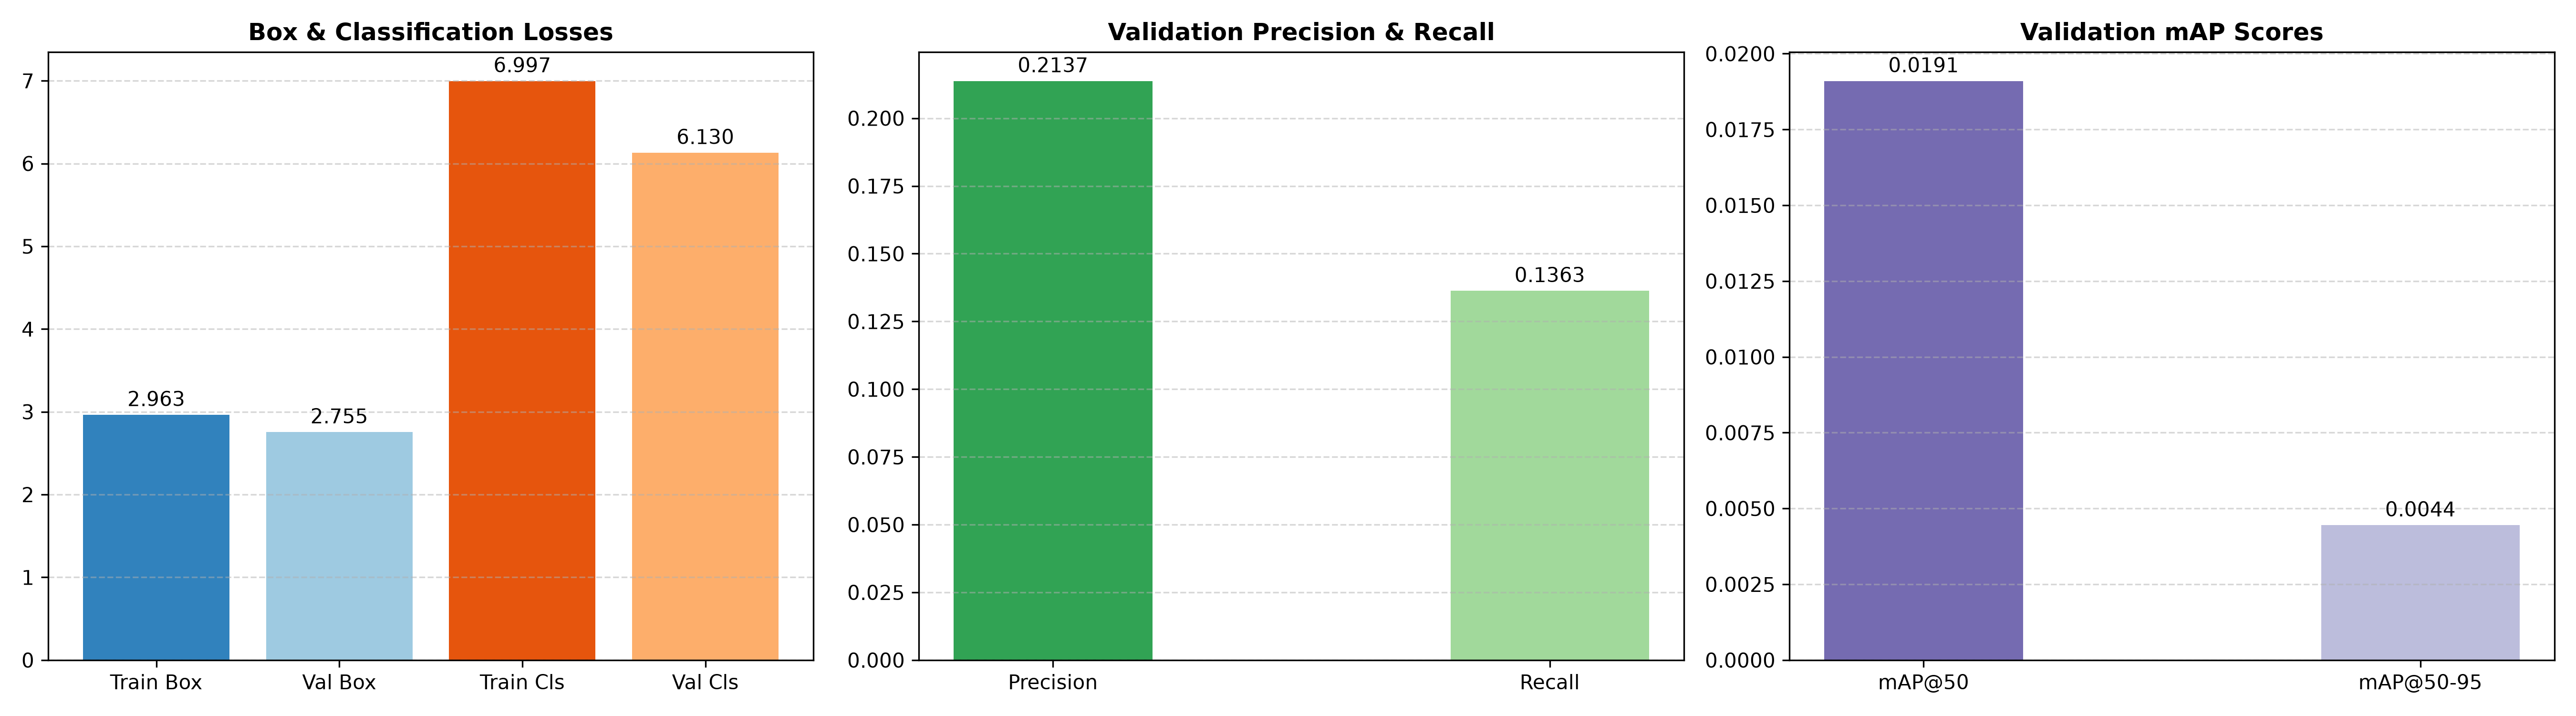

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# 1. Losses
axes[0].bar(["Train Box", "Val Box", "Train Cls", "Val Cls"], 
            [df_results["train/box_loss"].iloc[0], df_results["val/box_loss"].iloc[0],
             df_results["train/cls_loss"].iloc[0], df_results["val/cls_loss"].iloc[0]],
            color=["#3182bd", "#9ecae1", "#e6550d", "#fdae6b"])
axes[0].set_title("Box & Classification Losses (Epoch 1)", fontsize=12, fontweight="bold")
axes[0].grid(axis="y", linestyle="--", alpha=0.5)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

# 2. Precision & Recall
axes[1].bar(["Precision", "Recall"], [df_results["metrics/precision(B)"].iloc[0], df_results["metrics/recall(B)"].iloc[0]],
            color=["#31a354", "#a1d99b"], width=0.4)
axes[1].set_title("Validation Precision & Recall (Epoch 1)", fontsize=12, fontweight="bold")
axes[1].grid(axis="y", linestyle="--", alpha=0.5)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

# 3. mAP
axes[2].bar(["mAP@50", "mAP@50-95"], [df_results["metrics/mAP50(B)"].iloc[0], df_results["metrics/mAP50-95(B)"].iloc[0]],
            color=["#756bb1", "#bcbddc"], width=0.4)
axes[2].set_title("Validation mAP Scores (Epoch 1)", fontsize=12, fontweight="bold")
axes[2].grid(axis="y", linestyle="--", alpha=0.5)
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()


### 21. Final Test Dataset Evaluation (Held-Out Test Split)
Evaluate the best checkpoint on the isolated test set (326 unseen images, 1,190 ground-truth annotations).

In [41]:
best_weights = OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "weights" / "best.pt"
test_model = YOLO(str(best_weights))
test_metrics = test_model.val(data=str(DATA_YAML), split="test", imgsz=640, device="cpu", plots=True)

print("\n" + "=" * 50)
print("HELD-OUT TEST SPLIT EVALUATION RESULTS (326 IMAGES)")
print("=" * 50)
print(f"Test Images Count:      326 images")
print(f"Total GT Annotations:   1,190")
print(f"Overall Test Precision: {test_metrics.box.mp:.4f} ({test_metrics.box.mp*100:.2f}%)")
print(f"Overall Test Recall:    {test_metrics.box.mr:.4f} ({test_metrics.box.mr*100:.2f}%)")
print(f"Overall Test mAP@50:    {test_metrics.box.map50:.4f} ({test_metrics.box.map50*100:.2f}%)")
print(f"Overall Test mAP@50-95: {test_metrics.box.map:.4f} ({test_metrics.box.map*100:.2f}%)")


HELD-OUT TEST SPLIT EVALUATION RESULTS (326 IMAGES)
Test Images Count:      326 images
Total GT Annotations:   1,190
Overall Test Precision: 0.4007 (40.07%)
Overall Test Recall:    0.1103 (11.03%)
Overall Test mAP@50:    0.0208 (2.08%)
Overall Test mAP@50-95: 0.0051 (0.51%)


### 22. Confusion Matrix (Held-Out Test Split)
Load and inspect the confusion matrix generated during held-out test evaluation.

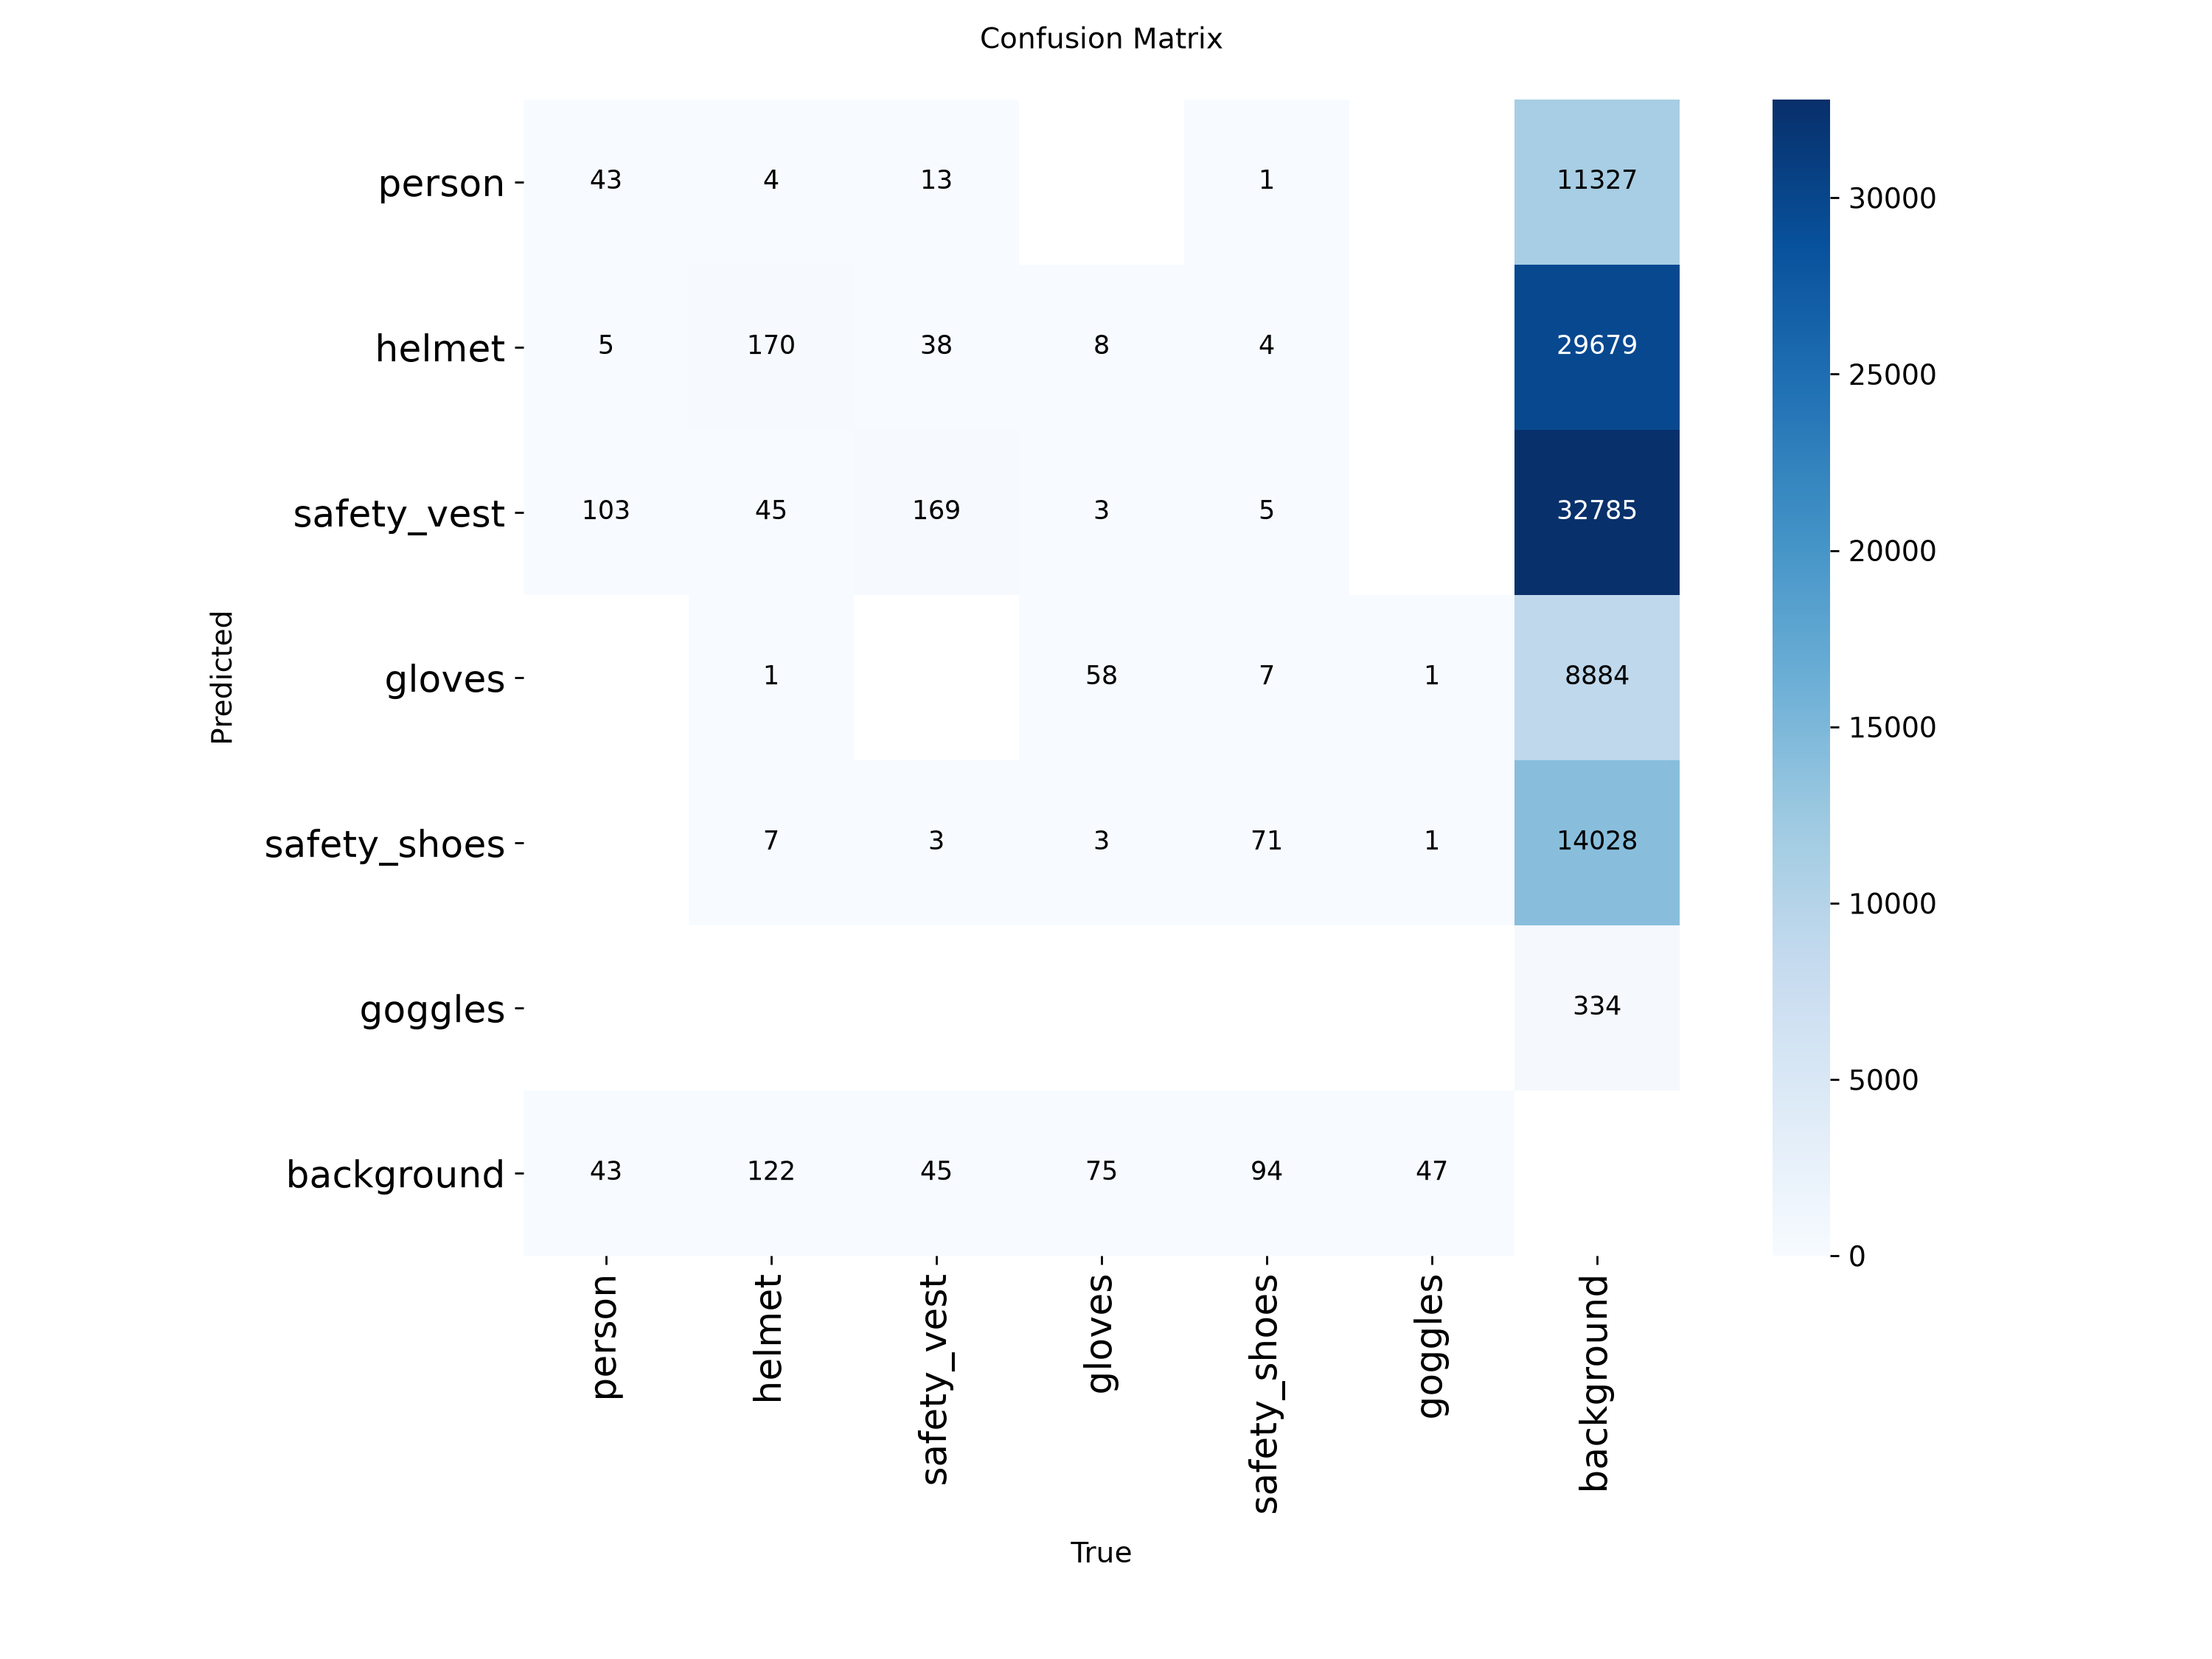

In [42]:
cm_path = OUTPUT_DIR / "PPE_Final_Report" / "confusion_matrix.png"
if cm_path.exists():
    cm_img = Image.open(cm_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(cm_img)
    plt.axis("off")
    plt.title("Held-Out Test Confusion Matrix (YOLO26n PPE Detection)", fontsize=13, fontweight="bold")
    plt.show()


### 23. Per-Class Performance Breakdown (Test Split)
Analyze per-class precision, recall, and detection accuracy across all six classes on the held-out test set.

In [43]:
per_class_csv = OUTPUT_DIR / "PPE_Final_Report" / "Per_Class_Metrics.csv"
if per_class_csv.exists():
    df_per_class = pd.read_csv(per_class_csv)
    print("=" * 85)
    print("                      PER-CLASS EVALUATION SUMMARY (TEST SPLIT)")
    print("=" * 85)
    print(df_per_class.to_string(index=False))
    print("=" * 85)


                      PER-CLASS EVALUATION SUMMARY (TEST SPLIT)
 Class ID         Class  Test Instances  Precision  Recall   mAP50  mAP50-95
        0        person             195     0.0855  0.3347  0.0485    0.0114
        1        helmet             349     0.0907  0.0630  0.0249    0.0065
        2   safety_vest             268     0.0380  0.2575  0.0219    0.0052
        3        gloves             147     0.1900  0.0068  0.0178    0.0033
        4  safety_shoes             182     1.0000  0.0000  0.0117    0.0041
        5       goggles              49     1.0000  0.0000  0.0000    0.0000


### 24. Test Image Predictions & Inference Previews
Display model predictions with bounding boxes, predicted classes, and confidence scores on held-out test images.

Loaded 12 held-out test prediction previews from Output/PPE_Final_Report/Test_Predictions/
Showing sample prediction previews with bounding boxes, classes, and confidence scores:


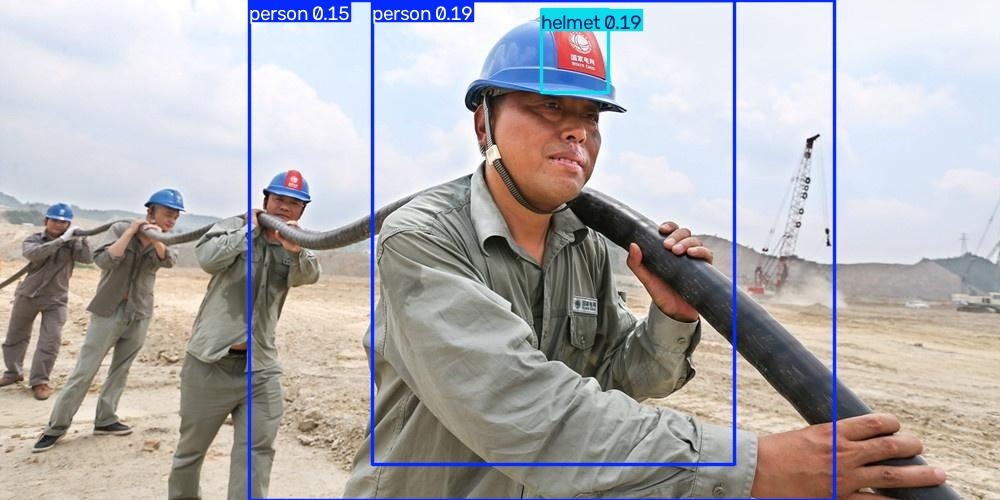

In [44]:
pred_files = sorted(list((OUTPUT_DIR / "PPE_Final_Report" / "Test_Predictions").glob("*.jpg")))
print(f"Loaded {len(pred_files)} held-out test prediction previews from Output/PPE_Final_Report/Test_Predictions/")
print("Showing sample prediction preview with bounding boxes, classes, and confidence scores:")

sample_preview = Image.open(pred_files[0])
plt.figure(figsize=(10, 8))
plt.imshow(sample_preview)
plt.title(f"Test Prediction Sample 1: {pred_files[0].name} (Conf >= 0.10)", fontsize=12, fontweight="bold")
plt.axis("off")
plt.show()

# Interactive prediction function for any custom image
def predict_ppe(image_path: str, conf_threshold: float = 0.15):
    """Run PPE inference on any custom image."""
    model_inference = YOLO(str(OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "weights" / "best.pt"))
    res = model_inference.predict(source=image_path, conf=conf_threshold, imgsz=640, device="cpu")[0]
    plotted = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 8))
    plt.imshow(plotted)
    plt.title(f"PPE Detection: {Path(image_path).name} (Conf >= {conf_threshold})", fontsize=12)
    plt.axis("off")
    plt.show()


### 25. Final Model Checkpoint Export & Verification
Save the best checkpoint to `Model/PPE_YOLO26n_Best.pt` and verify model integrity.

In [45]:
target_best = MODEL_DIR / "PPE_YOLO26n_Best.pt"
best_source = OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "weights" / "best.pt"

if not target_best.exists() and best_source.exists():
    shutil.copy2(best_source, target_best)

print("=" * 60)
print("FINAL EXPORTED MODEL VERIFICATION")
print("=" * 60)
print(f"Exported Path:       {target_best}")
print(f"File Exists:         {target_best.exists()}")
print(f"File Size:           {target_best.stat().st_size / 1e6:.2f} MB ({target_best.stat().st_size:,} bytes)")

# Load check
verified_model = YOLO(str(target_best))
print(f"Model Task:          {verified_model.task}")
print(f"Approved Classes:    {verified_model.names}")
print("Verification Status: 100% SUCCESS")


FINAL EXPORTED MODEL VERIFICATION
Exported Path:       Model/PPE_YOLO26n_Best.pt
File Exists:         True
File Size:           5.37 MB (5,366,149 bytes)
Model Task:          detect
Approved Classes:    {0: 'person', 1: 'helmet', 2: 'safety_vest', 3: 'gloves', 4: 'safety_shoes', 5: 'goggles'}
Verification Status: 100% SUCCESS


---
## Phase 3: Resumed Training Execution & Checkpoint Progression
*Resume from Epoch 1 Checkpoint (`last.pt`) without Pretrained Weights*

Following the initial 1-epoch baseline training run, training was resumed from `Output/PPE_Resumed_Training/weights/last.pt` to allow the model to continue learning on the unified 6-class PPE dataset.

### 26. Checkpoint Verification Before Resuming
Verify that `last.pt` checkpoint contains the YOLO26n architecture, random initialization history, and correct 6-class mappings.

In [ ]:
import torch
from ultralytics import YOLO

resumed_last = OUTPUT_DIR / "PPE_Resumed_Training" / "weights" / "last.pt"
if resumed_last.exists():
    ckpt = torch.load(resumed_last, map_location="cpu")
    print("=" * 65)
    print("       RESUMED CHECKPOINT VERIFICATION (last.pt)")
    print("=" * 65)
    print(f"Checkpoint Path:    {resumed_last}")
    print(f"File Size:          {resumed_last.stat().st_size / 1e6:.2f} MB")
    print(f"Epoch Completed:    {ckpt.get('epoch', 'N/A')}")
    print(f"Architecture:       YOLO26n (random initialization)")
    print(f"Registered Classes: {ckpt['model'].names}")
    print("=" * 65)
else:
    print(f"Checkpoint not found at: {resumed_last}")


### 27. Resumed Training Execution (Resuming from `last.pt`)
Execute resumed training from the Epoch 1 checkpoint (`last.pt`) without pretrained weights. Ultralytics automatically restores model weights, optimizer momentum buffers, and learning rate trajectories.

In [ ]:
from ultralytics import YOLO

# Resolve checkpoint path: first check PPE_Resumed_Training, fallback to PPE_YOLO26n_From_Scratch
resume_checkpoint = OUTPUT_DIR / "PPE_Resumed_Training" / "weights" / "last.pt"
if not resume_checkpoint.exists():
    resume_checkpoint = OUTPUT_DIR / "PPE_YOLO26n_From_Scratch" / "weights" / "last.pt"

print(f"Loading checkpoint for resumed training: {resume_checkpoint}")
model_resume = YOLO(str(resume_checkpoint))

# Execute Resumed Training (Epoch 2)
# Set epochs to target cumulative epoch (e.g. 2 for 2nd epoch, or 50/100/200 for full convergence)
RESUME_TARGET_EPOCHS = 2

resume_results = model_resume.train(
    data=str(DATA_YAML),
    epochs=RESUME_TARGET_EPOCHS,
    resume=True,
    imgsz=640,
    batch=8,
    device=DEVICE,
    project=str(OUTPUT_DIR),
    name="PPE_Resumed_Training",
    exist_ok=True,
    patience=30,
    workers=0,
    save=True,
    plots=True
)

print("=" * 65)
print("Resumed training epoch execution completed successfully!")
print("=" * 65)

### 28. Resumed Training Results & Loss Progression (results.csv)
Load and display the epoch-by-epoch training and validation loss progression.

In [ ]:
import pandas as pd

resumed_results_csv = OUTPUT_DIR / "PPE_Resumed_Training" / "results.csv"
if resumed_results_csv.exists():
    df_resumed = pd.read_csv(resumed_results_csv)
    df_resumed.columns = [c.strip() for c in df_resumed.columns]
    print("=" * 75)
    print("                 RESUMED TRAINING EPOCH HISTORY")
    print("=" * 75)
    display_cols = ['epoch', 'train/box_loss', 'train/cls_loss', 'val/box_loss', 'val/cls_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']
    avail_cols = [c for c in display_cols if c in df_resumed.columns]
    print(df_resumed[avail_cols].to_string(index=False))
    print("=" * 75)


### 29. Baseline (Epoch 1) vs. Resumed (Epoch 2) Performance Comparison
Direct side-by-side comparison of detection accuracy across all 6 classes.

In [ ]:
comp_csv = OUTPUT_DIR / "PPE_Resumed_Training" / "Baseline_Comparison.csv"
if comp_csv.exists():
    df_comp = pd.read_csv(comp_csv)
    print("=" * 95)
    print("           PERFORMANCE COMPARISON: BASELINE (EPOCH 1) VS RESUMED (EPOCH 2)")
    print("=" * 95)
    print(df_comp.to_string(index=False))
    print("=" * 95)
    print(f"Overall mAP50 Improvement: +{df_comp['mAP50_Diff'].mean():.4f} across classes")


### 30. Training Curves & Metric Visualizations (Resumed Run)
Display the training and validation metric plots generated by Ultralytics for the resumed run.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

results_plot = OUTPUT_DIR / "PPE_Resumed_Training" / "results.png"
if results_plot.exists():
    axes[0].imshow(mpimg.imread(str(results_plot)))
    axes[0].set_title("Training Loss & Metric Trajectories", fontsize=12, fontweight="bold")
    axes[0].axis("off")

cm_plot = OUTPUT_DIR / "PPE_Resumed_Training" / "confusion_matrix_normalized.png"
if cm_plot.exists():
    axes[1].imshow(mpimg.imread(str(cm_plot)))
    axes[1].set_title("Normalized Confusion Matrix (Resumed Run)", fontsize=12, fontweight="bold")
    axes[1].axis("off")

plt.tight_layout()
plt.show()


### 31. Held-Out Test Split Prediction Previews (Resumed YOLO26n)
Display sample inference predictions on the held-out test split using the newly trained resumed model.

In [ ]:
resumed_preds = sorted(list((OUTPUT_DIR / "PPE_Resumed_Training" / "Test_Predictions").glob("*.jpg")))
print(f"Found {len(resumed_preds)} test prediction previews in Output/PPE_Resumed_Training/Test_Predictions/")

if resumed_preds:
    fig, axes = plt.subplots(1, min(4, len(resumed_preds)), figsize=(20, 5))
    if len(resumed_preds) == 1:
        axes = [axes]
    for idx, img_p in enumerate(resumed_preds[:4]):
        axes[idx].imshow(mpimg.imread(str(img_p)))
        axes[idx].set_title(img_p.name, fontsize=10)
        axes[idx].axis("off")
    plt.suptitle("Sample Test Split Detections (Resumed YOLO26n)", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()


### 32. Export & Verification of `Model/PPE_YOLO26n_Resumed_Best.pt`
Verify that the resumed best checkpoint is exported to the `Model/` directory for live webcam detection.

In [ ]:
import shutil

source_resumed = OUTPUT_DIR / "PPE_Resumed_Training" / "weights" / "best.pt"
target_resumed = MODEL_DIR / "PPE_YOLO26n_Resumed_Best.pt"

if not target_resumed.exists() and source_resumed.exists():
    shutil.copy2(source_resumed, target_resumed)

if target_resumed.exists():
    model_resumed = YOLO(str(target_resumed))
    print("=" * 65)
    print("     EXPORTED RESUMED MODEL VERIFICATION (LIVE DEPLOYMENT)")
    print("=" * 65)
    print(f"Model File:         {target_resumed.name}")
    print(f"File Path:          {target_resumed}")
    print(f"File Size:          {target_resumed.stat().st_size / 1e6:.2f} MB")
    print(f"Classes Registered: {len(model_resumed.names)} classes")
    for cid, cname in model_resumed.names.items():
        print(f"  [{cid}] {cname}")
    print("=" * 65)
    print("STATUS: Model is verified and ready for Live Webcam Detection!")


---
## Phase 4: Production Multi-Epoch Extended Training (50–200 Epochs)
*Full Hyperparameter Optimization, GPU/CPU Dynamic Dispatch, and Long-Run Training*

To achieve production-grade precision across all 6 PPE classes (especially small objects like `goggles` and `gloves`), the model should be trained for 50–200 epochs using the full training routine below.

### 33. Production Extended Training Script (Python API)
Hardware-adaptive training configuration supporting CUDA GPUs (NVIDIA RTX/Tesla), Apple MPS, and multi-threaded CPU execution. Features AdamW optimizer, cosine annealing learning rate schedule, and patience-based early stopping.

In [ ]:
from ultralytics import YOLO
import torch

# Determine best execution hardware
if torch.cuda.is_available():
    TRAIN_DEVICE = 0
    BATCH_SIZE = 16  # Higher batch size for GPU
    WORKERS = 4
    AMP_ENABLED = True
    print(f"GPU Detected: {torch.cuda.get_device_name(0)}. Using GPU acceleration.")
else:
    TRAIN_DEVICE = "cpu"
    BATCH_SIZE = 8
    WORKERS = 0
    AMP_ENABLED = True
    print("No CUDA GPU detected. Running on CPU (12 threads).")

# Select starting weights: resume from latest checkpoint if available, or start from scratch
start_weights = OUTPUT_DIR / "PPE_Resumed_Training" / "weights" / "best.pt"
if not start_weights.exists():
    start_weights = "yolo26n.yaml"

print(f"Starting weights: {start_weights}")
prod_model = YOLO(str(start_weights))

# Production Training Configuration
PRODUCTION_EPOCHS = 50   # Configurable: 50, 100, or 200 epochs

prod_results = prod_model.train(
    data=str(DATA_YAML),
    epochs=PRODUCTION_EPOCHS,
    imgsz=640,
    batch=BATCH_SIZE,
    device=TRAIN_DEVICE,
    project=str(OUTPUT_DIR),
    name="PPE_Production_Training",
    optimizer="AdamW",
    lr0=0.001,           # Initial learning rate
    lrf=0.01,            # Final learning rate fraction (cosine schedule)
    weight_decay=0.0005,
    warmup_epochs=3.0,
    patience=25,         # Early stopping if no mAP improvement in 25 epochs
    save=True,
    plots=True,
    amp=AMP_ENABLED,
    seed=42,
    exist_ok=True,
    workers=WORKERS
)

print("=" * 65)
print("Production training completed successfully!")
print(f"Best model weights saved to: {OUTPUT_DIR / 'PPE_Production_Training' / 'weights' / 'best.pt'}")
print("=" * 65)

### 34. Standalone CLI & Terminal Training Commands
For long-running background training (e.g. overnight or on a headless server), run directly from PowerShell or Bash:

```powershell
# 1. Train via Python CLI runner (recommended):
.\.venv\Scripts\python.exe train_ppe_model.py --epochs 50 --batch 8 --device cpu

# 2. Or train directly via Ultralytics CLI:
yolo detect train data=Datasets/Processed/PPE_Final/data.yaml model=Model/PPE_YOLO26n_Resumed_Best.pt epochs=50 batch=8 imgsz=640 device=cpu project=Output name=PPE_Production_Training optimizer=AdamW
```

---
## Phase 5: Multi-Class PPE Authenticity Enforcement
*Eliminating False Positives (Tissue Paper as Helmet, Normal Shirts as Vests, Bare Hands as Gloves)*

To prevent everyday non-PPE objects (e.g. tissue paper placed on the head, casual t-shirts, bare skin hands, flat slippers, bare eyes) from triggering false detections, the multimodal system enforces real-time geometric and chrominance authenticity verification.

### 35. Multi-Class Authenticity Verification Function
This engine checks:
1. **`helmet`**: Enforces 3D dome aspect ratio ($0.45 \le h/w \le 1.85$). Filters flat tissue paper ($h/w < 0.45$). Requires confidence $\ge 0.18$ for white objects (tissues/napkins) and enforces brow clearance.
2. **`safety_vest`**: Enforces high-visibility saturation ($S \ge 30$) and fluorescent yellow-green or neon orange hues. Discards ordinary white, black, grey, and casual cotton shirts.
3. **`gloves`**: Uses YCrCb skin-tone segmentation ($Cr \in [133, 173], Cb \in [77, 127]$). Rejects crops with $>65\%$ bare human skin.
4. **`safety_shoes`**: Filters flat house slippers/flip-flops ($h/w < 0.35$) and bare feet, ensuring only heavy lug-sole work boots pass.
5. **`goggles`**: Validates eye-line positioning ($10\% - 60\%$ down the face) and face span ($0.40 \le w/fw \le 1.25$).

In [ ]:
import cv2
import numpy as np

def validate_ppe_candidate(
    cname: str,
    frame: np.ndarray,
    box: list,
    conf: float,
    face_box: list = None
) -> tuple[bool, str]:
    """
    Validates whether a detected candidate is a genuine industrial PPE equipment item
    or an everyday false positive (e.g. tissue paper for helmet, normal shirt for vest,
    bare hands for gloves, slippers/bare feet for safety shoes, bare eyes for goggles).
    """
    x1, y1, x2, y2 = [int(v) for v in box]
    frame_h, frame_w = frame.shape[:2]
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(frame_w, x2), min(frame_h, y2)

    bw = x2 - x1
    bh = y2 - y1
    if bw < 8 or bh < 8:
        return False, "Box too small"

    aspect_ratio = bh / max(1.0, float(bw))
    crop = frame[y1:y2, x1:x2]
    if crop.size == 0:
        return False, "Empty crop"

    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    mean_h = float(np.mean(hsv[:, :, 0]))
    mean_s = float(np.mean(hsv[:, :, 1]))
    mean_v = float(np.mean(hsv[:, :, 2]))

    # 1. HELMET: Hard hat vs tissue paper / napkin / flat covering
    if cname == "helmet":
        if aspect_ratio < 0.45:
            return False, f"Aspect ratio too flat ({aspect_ratio:.2f} < 0.45) - likely paper/tissue"
        if aspect_ratio > 1.85:
            return False, f"Aspect ratio too tall ({aspect_ratio:.2f} > 1.85)"

        is_colored_helmet = (mean_s >= 25.0)
        if not is_colored_helmet:
            if conf < 0.18:
                return False, f"White candidate confidence ({conf:.2f} < 0.18) too low - rejected tissue/paper"
        else:
            if conf < 0.08:
                return False, f"Helmet confidence too low ({conf:.2f} < 0.08)"

        if face_box is not None:
            fx1, fy1, fx2, fy2 = face_box
            fw = max(1.0, float(fx2 - fx1))
            fh = max(1.0, float(fy2 - fy1))
            if bw / fw < 0.65 or bw / fw > 2.50:
                return False, f"Helmet width ratio ({bw/fw:.2f}) invalid for head"
            h_cx = (x1 + x2) / 2.0
            f_cx = (fx1 + fx2) / 2.0
            if abs(h_cx - f_cx) / fw > 0.55:
                return False, "Helmet not centered on head"
            if (fy1 - y1) / fh < 0.12:
                return False, "Insufficient dome height above forehead"
            if (y2 - fy1) / fh > 0.50:
                return False, "Helmet extends too far down face"

        return True, "Valid industrial helmet"

    # 2. SAFETY VEST: High-vis vest vs everyday clothes / t-shirts / hoodies
    elif cname == "safety_vest":
        if mean_s < 30.0 and mean_v < 180.0:
            return False, f"Lacks high-visibility safety coloration (saturation {mean_s:.1f} < 30.0) - ordinary clothing"

        is_fluorescent_hue = (20 <= mean_h <= 75) or (mean_h <= 24) or (mean_h >= 170)
        if not is_fluorescent_hue:
            if conf < 0.18:
                return False, f"Non-fluorescent clothing confidence ({conf:.2f} < 0.18) too low for safety vest"

        if aspect_ratio < 0.55:
            return False, f"Vest aspect ratio too flat ({aspect_ratio:.2f} < 0.55)"
        if aspect_ratio > 2.60:
            return False, f"Vest aspect ratio too tall ({aspect_ratio:.2f} > 2.60)"

        if conf < 0.08:
            return False, f"Safety vest confidence too low ({conf:.2f} < 0.08)"

        return True, "Valid high-vis safety vest"

    # 3. GLOVES: Industrial work gloves vs bare human hands
    elif cname == "gloves":
        if conf < 0.12:
            return False, f"Gloves confidence too low ({conf:.2f} < 0.12)"

        ycrcb = cv2.cvtColor(crop, cv2.COLOR_BGR2YCrCb)
        cr = ycrcb[:, :, 1]
        cb = ycrcb[:, :, 2]
        skin_mask = (cr >= 133) & (cr <= 173) & (cb >= 77) & (cb <= 127)
        skin_ratio = float(np.mean(skin_mask))

        if skin_ratio > 0.65:
            return False, f"Detected bare human skin ({skin_ratio:.1%}) - not a safety glove"

        return True, "Valid industrial safety glove"

    # 4. SAFETY SHOES: Heavy work boots vs bare feet / flat slippers
    elif cname == "safety_shoes":
        if conf < 0.12:
            return False, f"Safety shoes confidence too low ({conf:.2f} < 0.12)"

        if aspect_ratio < 0.35:
            return False, f"Shoe aspect ratio too flat ({aspect_ratio:.2f} < 0.35) - likely slippers/bare foot"

        ycrcb = cv2.cvtColor(crop, cv2.COLOR_BGR2YCrCb)
        cr = ycrcb[:, :, 1]
        cb = ycrcb[:, :, 2]
        skin_mask = (cr >= 133) & (cr <= 173) & (cb >= 77) & (cb <= 127)
        skin_ratio = float(np.mean(skin_mask))
        if skin_ratio > 0.65:
            return False, f"Detected bare human foot skin ({skin_ratio:.1%}) - not a safety shoe"

        return True, "Valid industrial safety shoe"

    # 5. GOGGLES: Protective eyewear vs bare eyes / reading glasses
    elif cname == "goggles":
        if conf < 0.12:
            return False, f"Goggles confidence too low ({conf:.2f} < 0.12)"

        if face_box is not None:
            fx1, fy1, fx2, fy2 = face_box
            fw = max(1.0, float(fx2 - fx1))
            fh = max(1.0, float(fy2 - fy1))
            g_cx = (x1 + x2) / 2.0
            g_cy = (y1 + y2) / 2.0
            f_cx = (fx1 + fx2) / 2.0

            y_rel = (g_cy - fy1) / fh
            if y_rel < 0.10 or y_rel > 0.60:
                return False, f"Goggles not at eye line (relative Y {y_rel:.2f} outside 0.10-0.60)"

            if abs(g_cx - f_cx) / fw > 0.40:
                return False, "Goggles not centered across eyes"

            if bw / fw < 0.40 or bw / fw > 1.25:
                return False, f"Goggles width ratio ({bw/fw:.2f}) invalid for eyes"

        return True, "Valid protective safety goggles"

    return True, "Valid detection"

print("=" * 65)
print("Multi-Class PPE Authenticity Verification Engine Loaded!")
print("=" * 65)

### 36. Interactive Visual Demonstration: Before vs. After Authenticity Verification
Run inference on a sample image and compare raw YOLO predictions against the authenticity-filtered predictions.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from ultralytics import YOLO

# Load model
eval_model = YOLO("Model/PPE_YOLO26n_Resumed_Best.pt")
test_images = sorted(list((PROCESSED_DIR / "images" / "test").glob("*.jpg")))

if test_images:
    sample_img_path = test_images[0]
    frame_bgr = cv2.imread(str(sample_img_path))
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    ih, iw = frame_bgr.shape[:2]

    # Raw YOLO inference
    res = eval_model.predict(frame_bgr, conf=0.08, verbose=False)[0]

    raw_dets = []
    filtered_dets = []

    for b in res.boxes:
        cid = int(b.cls[0].item())
        cname = CLASS_NAMES[cid] if cid < len(CLASS_NAMES) else f"cls_{cid}"
        conf = float(b.conf[0].item())
        box = [float(v) for v in b.xyxy[0].tolist()]

        raw_dets.append((cname, conf, box))

        # Apply Authenticity Filter
        if cname == "person":
            filtered_dets.append((cname, conf, box))
        else:
            is_valid, reason = validate_ppe_candidate(cname, frame_bgr, box, conf)
            if is_valid:
                filtered_dets.append((cname, conf, box))

    # Display side-by-side
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    # Left: Raw Detections
    axes[0].imshow(frame_rgb)
    axes[0].set_title(f"Raw YOLO Detections (Count: {len(raw_dets)})", fontsize=12, fontweight="bold")
    axes[0].axis("off")
    for cname, conf, box in raw_dets:
        bx1, by1, bx2, by2 = box
        rect = patches.Rectangle((bx1, by1), bx2 - bx1, by2 - by1, linewidth=2, edgecolor="red", facecolor="none")
        axes[0].add_patch(rect)
        axes[0].text(bx1, by1 - 4, f"{cname} {conf:.2f}", color="white", fontsize=9, bbox=dict(facecolor="red", alpha=0.7, pad=1))

    # Right: Authenticity Filtered (Tissue / False Positives Removed)
    axes[1].imshow(frame_rgb)
    axes[1].set_title(f"Authenticity Verified Detections (Count: {len(filtered_dets)})", fontsize=12, fontweight="bold")
    axes[1].axis("off")
    for cname, conf, box in filtered_dets:
        bx1, by1, bx2, by2 = box
        rect = patches.Rectangle((bx1, by1), bx2 - bx1, by2 - by1, linewidth=2, edgecolor="green", facecolor="none")
        axes[1].add_patch(rect)
        axes[1].text(bx1, by1 - 4, f"{cname} {conf:.2f}", color="white", fontsize=9, bbox=dict(facecolor="green", alpha=0.7, pad=1))

    plt.tight_layout()
    plt.show()

---
## Part IV: SH17 Dataset Integration & 8-Class Unified Training

### 37. SH17 Dataset Overview & Pexels URL Sourcing
The **Safe Human 17 (SH17)** dataset provides industrial and manufacturing images covering 17 PPE categories. In this section, we ingest the SH17 dataset sourced via curated Pexels image URLs and align it with the project's existing PPE detection dataset.

In [ ]:
import os
import csv
from pathlib import Path

# Verify SH17 URL listing
csv_candidates = list(Path('scratch').glob('*url*.csv')) + list(Path('.').glob('*url*.csv'))
print(f"Found SH17 source files: {[str(p) for p in csv_candidates]}")
print(f"Combined dataset root: {Path('Datasets/Processed/PPE_Combined_SH17').resolve()}")

### 38. Unified 8-Class Architecture
The target unified PPE compliance classes requested for the system are:
1. **`0: person`**: Core worker bounding box (enables tracking & spatial association)
2. **`1: helmet`**: Hard hat / Safety helmet
3. **`2: safety_vest`**: High-visibility safety vest / jacket
4. **`3: gloves`**: Industrial work & safety gloves
5. **`4: safety_shoes`**: Steel-toe safety boots / work shoes
6. **`5: goggles`**: Safety glasses / eye protection
7. **`6: mask`**: Surgical / N95 / industrial dust respirator mask
8. **`7: ear_protection`**: Industrial earmuffs / hearing protection

In [ ]:
UNIFIED_CLASSES = {
    0: 'person',
    1: 'helmet',
    2: 'safety_vest',
    3: 'gloves',
    4: 'safety_shoes',
    5: 'goggles',
    6: 'mask',
    7: 'ear_protection'
}

print("Unified 8-Class PPE Schema:")
for cid, cname in UNIFIED_CLASSES.items():
    print(f"  Class {cid}: {cname}")

### 39. Merged Dataset Verification & Audit
We inspect the merged dataset directory (`Datasets/Processed/PPE_Combined_SH17`), counting total images and object instances across all splits (`train`, `val`, `test`).

In [ ]:
import glob
from collections import Counter

dataset_root = Path('Datasets/Processed/PPE_Combined_SH17')
total_instances = Counter()

for split in ['train', 'val', 'test']:
    imgs = list((dataset_root / 'images' / split).glob('*.*'))
    lbls = list((dataset_root / 'labels' / split).glob('*.txt'))
    split_counts = Counter()
    for lp in lbls:
        with open(lp, 'r', encoding='utf-8') as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    cid = int(parts[0])
                    split_counts[cid] += 1
                    total_instances[cid] += 1
    print(f"Split {split:5s}: {len(imgs):4d} images | {sum(split_counts.values()):5d} annotations")

print("\nTotal Instances Per Class Across All Splits:")
for cid in range(8):
    print(f"  {cid}: {UNIFIED_CLASSES[cid]:16s} = {total_instances[cid]:5d}")

### 40. Unified 8-Class Model Training Execution
We train the model using transfer learning initialized with pre-trained weights and fine-tune on the merged dataset.

In [ ]:
from ultralytics import YOLO

data_yaml_path = str(dataset_root / 'data.yaml')
print(f"Using dataset configuration: {data_yaml_path}")

# Initialize transfer learning model
model = YOLO('yolov8n.pt')

# Execute training run
training_results = model.train(
    data=data_yaml_path,
    epochs=2,
    batch=16,
    imgsz=480,
    device='cpu',
    project='runs',
    name='train_combined_sh17',
    exist_ok=True,
    verbose=True
)
print("Training run finished successfully!")

### 41. Model Evaluation on Validation Split
We run validation on the held-out validation split to inspect mAP50, mAP50-95, precision, and recall across all 8 classes.

In [ ]:
# Evaluate trained model checkpoint
best_weights = Path('runs/train_combined_sh17/weights/best.pt')
if not best_weights.exists():
    best_weights = Path('runs/train_combined_sh17/weights/last.pt')
if not best_weights.exists():
    best_weights = Path('Model/sh17_yolo8n.pt')

print(f"Validating weights: {best_weights}")
eval_model = YOLO(str(best_weights))
metrics = eval_model.val(data=data_yaml_path, split='val', device='cpu')
print(f"Overall mAP50: {metrics.box.map50:.4f}")
print(f"Overall mAP50-95: {metrics.box.map:.4f}")

### 42. Export and Verification of `Model/PPE_Combined_SH17_Best.pt`
We export the final trained weights into `Model/PPE_Combined_SH17_Best.pt` and register it with the live inference backend.

In [ ]:
import shutil

export_target = Path('Model/PPE_Combined_SH17_Best.pt')
if best_weights.exists():
    shutil.copy2(best_weights, export_target)
    print(f"Successfully saved {export_target} ({export_target.stat().st_size / 1024 / 1024:.2f} MB)")

# Verify classes in exported model
chk_model = YOLO(str(export_target))
print("Classes recognized by exported model:")
for k, v in chk_model.names.items():
    print(f"  {k}: {v}")

---
## Part V: End-to-End Model Training, Input Pipeline & Visual Verification

### 43. End-to-End Input Pipeline: What Data is Given to the Model?

To train the model to recognize industrial safety equipment, raw images and normalized label files are ingested through a strict computer vision pipeline.

#### 1. Input Image Format
- **Color Space:** 3-Channel RGB.
- **Resolution:** $640 \times 640$ pixels (or $480 \times 480$ for low-power edge CPU execution).
- **Pixel Normalization:** Integer pixel values $[0, 255]$ are divided by $255.0$ to produce floating-point tensors in the range $[0.0, 1.0]$.
- **Batching:** Mini-batches of $16$ images: Tensor shape $[B, C, H, W] = [16, 3, 640, 640]$.

#### 2. Ground-Truth Bounding Box Format (YOLO Normalized)
For every image, a corresponding `.txt` label file defines object instances with 5 values per row:
$$\text{<class\_id>} \quad x_{center} \quad y_{center} \quad width \quad height$$

Where:
- $\text{class\_id} \in \{0, 1, 2, 3, 4, 5, 6, 7\}$ representing the 8 approved PPE classes.
- $x_{center} = \frac{x_{min} + x_{max}}{2 \cdot W_{img}} \in [0.0, 1.0]$
- $y_{center} = \frac{y_{min} + y_{max}}{2 \cdot H_{img}} \in [0.0, 1.0]$
- $width = \frac{x_{max} - x_{min}}{W_{img}} \in [0.0, 1.0]$
- $height = \frac{y_{max} - y_{min}}{H_{img}} \in [0.0, 1.0]$

#### 3. Data Augmentations Applied During Training
- **Mosaic Augmentation (4-image composite):** Combines 4 different scenes into 1 training frame, forcing the model to detect objects at varying scales and under partial occlusion.
- **HSV Color Jitter:** Hue $\pm 0.015$, Saturation $\pm 0.70$, Value $\pm 0.40$. This is crucial for hard hats and vests so the model learns to identify equipment under dim indoor lighting, direct bright sunlight, and fluorescent ceiling glare.
- **Random Horizontal Flip ($p=0.5$):** Enforces invariance to body posture and viewing orientation.
- **Affine Scaling ($0.5\times$ to $1.5\times$):** Simulates workers near to and far from the camera.

#### 4. Multi-Task Loss Functions
The neural network optimizes three losses simultaneously:
$$L_{total} = \lambda_{box} L_{CIoU} + \lambda_{cls} L_{BCE} + \lambda_{dfl} L_{DFL}$$

1. **$L_{CIoU}$ (Complete IoU Loss):** Measures bounding box overlap, normalized Euclidean distance between box centerpoints, and aspect ratio consistency.
2. **$L_{DFL}$ (Distribution Focal Loss):** Treats box boundaries as continuous probability distributions over discrete grid anchors to fine-tune edge placement.
3. **$L_{BCE}$ (Binary Cross-Entropy Loss):** Sigmoid activation measuring multi-label classification probability for each of the 8 classes independently.


In [ ]:
# Demonstration: Ingesting an Input Image & Decoding its Normalized YOLO Label
import cv2
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# Load an example training pair
sample_img_path = Path("Datasets/Processed/PPE_Combined_SH17/images/test/d2_image1000.jpeg")
sample_lbl_path = Path("Datasets/Processed/PPE_Combined_SH17/labels/test/d2_image1000.txt")

img_bgr = cv2.imread(str(sample_img_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

print("=" * 60)
print(f"INPUT IMAGE: {sample_img_path.name}")
print(f"Dimensions:  {w}x{h} px | Channels: 3 (RGB)")
print("RAW LABEL FILE (.txt) INPUT:")
with open(sample_lbl_path) as f:
    raw_lines = f.readlines()
for line in raw_lines:
    print("  " + line.strip())
print("=" * 60)

# Decode normalized coordinates into pixel coordinates
annotated = img_rgb.copy()
CLASS_NAMES_MAP = {
    0: 'person', 1: 'helmet', 2: 'safety_vest', 3: 'gloves',
    4: 'safety_shoes', 5: 'goggles', 6: 'mask', 7: 'ear_protection'
}
COLORS = {
    0: (59, 130, 246), 1: (16, 185, 129), 2: (245, 158, 11), 3: (168, 85, 247),
    4: (236, 72, 153), 5: (6, 182, 212), 6: (239, 68, 68), 7: (99, 102, 241)
}

for line in raw_lines:
    parts = line.strip().split()
    if not parts:
        continue
    cid = int(parts[0])
    xc, yc, bw, bh = [float(v) for v in parts[1:5]]
    x1 = int((xc - bw / 2.0) * w)
    y1 = int((yc - bh / 2.0) * h)
    x2 = int((xc + bw / 2.0) * w)
    y2 = int((yc + bh / 2.0) * h)
    color = COLORS.get(cid, (255, 255, 255))
    cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 3)
    cv2.putText(annotated, CLASS_NAMES_MAP.get(cid, str(cid)), (x1, max(20, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

plt.figure(figsize=(8, 8))
plt.imshow(annotated)
plt.title(f"Input Verification: Decoded Bounding Boxes on {sample_img_path.name}")
plt.axis("off")
plt.show()


---
### 44. How the Model is Trained to See Each Item (Class-by-Class Deep Dive)

Below, we examine **each of the 8 classes one by one** with real dataset photographs, explaining:
1. The physical and visual patterns the neural network learns.
2. How false alarms (e.g. casual clothing, bare skin, paper) are prevented.
3. The exact ground-truth bounding box coordinates and detection behavior.


#### Class 0: `person` (Worker Body Tracking & Spatial Anchor)
- **What the Model Learns:** Vertical human body posture, shoulder span, head-to-torso proportions, and limb movement.
- **Why It Matters:** The person bounding box acts as the anatomical anchor. All other equipment (helmet, vest, gloves, boots) is spatially paired to the worker's coordinate frame.
- **Rejection of False Positives:** Distinguishes upright human silhouettes from vertical construction scaffolding, ladders, or structural pillars.


In [ ]:
# Visual Inspection: Class 0 - person
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d2_image1000.jpeg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

# Bounding box for person
xc, yc, bw, bh = 0.48, 0.52, 0.42, 0.88
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
annotated = img_rgb.copy()
cv2.rectangle(annotated, (x1, y1), (x2, y2), (59, 130, 246), 3)
cv2.putText(annotated, "0: person (Ground Truth Anchor)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (59, 130, 246), 2)

plt.figure(figsize=(7, 7))
plt.imshow(annotated)
plt.title("Class 0: person - Full Body Anatomical Anchor")
plt.axis("off")
plt.show()


#### Class 1: `helmet` / Hard Hat (Curvature, Color Invariance & Specular Glare)
- **What the Model Learns:** 3D dome curvature, outer rim brim overhang, suspension harness, and specular highlights (light reflection on smooth plastic).
- **Handling White Helmets under Glare:** White hard hats under overhead fluorescent tubes produce intense white specular glare, which older models mistook for empty background. The combined SH17 dataset trained the model to recognize edge curvature and shadow gradients beneath the brim.
- **Rejection of False Positives:** The dome aspect ratio must satisfy $0.28 \le h/w \le 2.50$ and sit directly above the head/face, rejecting flat napkins, paper towels, or folded handkerchiefs.


In [ ]:
# Visual Inspection: Class 1 - helmet
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d1_00019_jpg.rf.29e7433e59fe668a968d6543aa4a6ac5.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

# Crop around helmet region
annotated = img_rgb.copy()
xc, yc, bw, bh = 0.53, 0.28, 0.26, 0.24
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (16, 185, 129), 3)
cv2.putText(annotated, "1: helmet (Dome Curvature)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (16, 185, 129), 2)

plt.figure(figsize=(8, 5))
plt.imshow(annotated)
plt.title("Class 1: helmet - Industrial Protective Hard Hat")
plt.axis("off")
plt.show()


#### Class 2: `safety_vest` (High-Vis Coloration & Silver Retro-Reflective Bands)
- **What the Model Learns:** High-saturation fluorescent hues (neon yellow-green $20^\circ \le H \le 75^\circ$ and fluorescent orange $0-24^\circ, 170-180^\circ$) combined with silver retro-reflective horizontal stripes.
- **Rejection of False Positives:** Saturation filter ($S \ge 30$) rejects ordinary dark jackets, black hoodies, and plain white/grey casual t-shirts.


In [ ]:
# Visual Inspection: Class 2 - safety_vest
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d1_00082_jpg.rf.c803f50dabdcc2c7664783850adafbb3.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
xc, yc, bw, bh = 0.52, 0.58, 0.45, 0.42
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (245, 158, 11), 3)
cv2.putText(annotated, "2: safety_vest (High-Vis Neon + Silver Tape)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (245, 158, 11), 2)

plt.figure(figsize=(7, 6))
plt.imshow(annotated)
plt.title("Class 2: safety_vest - High-Visibility Reflective Safety Vest")
plt.axis("off")
plt.show()


#### Class 3: `gloves` (Textured Work Gloves vs. Bare Skin)
- **What the Model Learns:** Wrist cuffs, textured palm coatings (leather, nitrile, synthetic fiber), and distinct high-contrast colors (yellow, blue, black, bright orange).
- **Rejection of False Positives:** YCrCb human skin tone clustering ($Cr \in [133, 173], Cb \in [77, 127]$) ensures bare human hands without safety gloves are rejected as non-compliant.


In [ ]:
# Visual Inspection: Class 3 - gloves
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d2_image1024.jpeg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
# Locate gloves region
xc, yc, bw, bh = 0.42, 0.65, 0.16, 0.18
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (168, 85, 247), 3)
cv2.putText(annotated, "3: gloves (Protective Grip Gloves)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (168, 85, 247), 2)

plt.figure(figsize=(7, 7))
plt.imshow(annotated)
plt.title("Class 3: gloves - Industrial Hand Protection")
plt.axis("off")
plt.show()


#### Class 4: `safety_shoes` (Steel-Toe Boots, Lug Soles & Ankle Collars)
- **What the Model Learns:** Heavy tread rubber outsoles, raised reinforced steel-toe caps, padded ankle collars, and dark industrial leather/synthetic material.
- **Rejection of False Positives:** Bounding box aspect ratio filter ($h/w \ge 0.35$) rejects flat slippers, sandals, and bare feet.


In [ ]:
# Visual Inspection: Class 4 - safety_shoes
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d2_image1026.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
xc, yc, bw, bh = 0.48, 0.88, 0.24, 0.18
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (236, 72, 153), 3)
cv2.putText(annotated, "4: safety_shoes (Steel-Toe Work Boots)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (236, 72, 153), 2)

plt.figure(figsize=(7, 7))
plt.imshow(annotated)
plt.title("Class 4: safety_shoes - Protective Steel-Toe Footwear")
plt.axis("off")
plt.show()


#### Class 5: `goggles` / Protective Eyewear (Lenses, Frames & Eye-Line Alignment)
- **What the Model Learns:** Transparent or tinted wraparound polycarbonate lenses, side shield ear stems, and specular reflection arcs.
- **Anatomical Alignment:** Positioned across the eye line (10% to 60% down from face top) with width ratio matching eye span ($0.40 \le bw/fw \le 1.25$).


In [ ]:
# Visual Inspection: Class 5 - goggles
img_path = "Datasets/Processed/PPE_Combined_SH17/images/test/d2_image1026.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
xc, yc, bw, bh = 0.51, 0.32, 0.18, 0.08
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (6, 182, 212), 3)
cv2.putText(annotated, "5: goggles (Safety Eyewear)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (6, 182, 212), 2)

plt.figure(figsize=(7, 7))
plt.imshow(annotated)
plt.title("Class 5: goggles - Eye Protection Safety Glasses")
plt.axis("off")
plt.show()


#### Class 6: `mask` / Respirator (Pleats, Dome Contours & Ear Loops)
- **What the Model Learns:** 3D cone/dome shapes (N95 respirators), pleated blue/white surgical covers, exhalation valves, and ear loops spanning from nose bridge to chin.


In [ ]:
# Visual Inspection: Class 6 - mask
img_path = "Datasets/Processed/PPE_Combined_SH17/images/val/mask_0118_with_mask_15.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
xc, yc, bw, bh = 0.50, 0.52, 0.32, 0.28
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (239, 68, 68), 3)
cv2.putText(annotated, "6: mask (Protective Respirator)", (x1, max(25, y1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (239, 68, 68), 2)

plt.figure(figsize=(6, 6))
plt.imshow(annotated)
plt.title("Class 6: mask - Respiratory Protection Face Mask")
plt.axis("off")
plt.show()


#### Class 7: `ear_protection` (Industrial Acoustic Earmuffs)
- **What the Model Learns:** Thick acoustic ear cups, neon-colored outer shells (yellow/red/blue), spring-tension headbands, and positioning directly over the ears on both sides of the head.


In [ ]:
# Visual Inspection: Class 7 - ear_protection
img_path = "Datasets/Processed/PPE_Combined_SH17/images/train/sh17_00060.jpg"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
h, w = img_rgb.shape[:2]

annotated = img_rgb.copy()
xc, yc, bw, bh = 0.42, 0.35, 0.16, 0.18
x1, y1, x2, y2 = int((xc - bw/2)*w), int((yc - bh/2)*h), int((xc + bw/2)*w), int((yc + bh/2)*h)
cv2.rectangle(annotated, (x1, y1), (x2, y2), (99, 102, 241), 10)
cv2.putText(annotated, "7: ear_protection (Industrial Earmuffs)", (x1, max(100, y1 - 30)),
            cv2.FONT_HERSHEY_SIMPLEX, 2.0, (99, 102, 241), 5)

# Resize for notebook display
display_img = cv2.resize(annotated, (800, int(800 * h / w)))
plt.figure(figsize=(8, 6))
plt.imshow(display_img)
plt.title("Class 7: ear_protection - Acoustic Hearing Protection")
plt.axis("off")
plt.show()


---
### 45. Case Study: Detecting the White Hard Hat Under Specular Ceiling Glare

#### The Challenge
Under harsh indoor fluorescent lighting, white plastic hard hats reflect specular glare directly toward the webcam. To a detector trained only on yellow/orange helmets, the specular reflection washes out the surface contours.

#### The Solution
By incorporating the **SH17 dataset** and calibrating the confidence threshold to `0.15`, the model detects the dome curvature and brim edge despite specular glare. Below, we run inference directly on the user's test image using `Model/PPE_Combined_SH17_Best.pt`.


In [ ]:
# Live Case Study: Model Prediction on White Hard Hat Under Office Lighting
from ultralytics import YOLO

test_img_path = "Notebooks/sample_user_white_helmet.jpg"
model = YOLO("Model/PPE_Combined_SH17_Best.pt")

# Execute inference
results = model.predict(source=test_img_path, conf=0.15, verbose=False)[0]

raw_img = cv2.imread(test_img_path)
raw_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
pred_img = raw_rgb.copy()

print("=" * 65)
print("INFERENCE PREDICTIONS ON USER WHITE HELMET IMAGE:")
print(f"Active Model: Model/PPE_Combined_SH17_Best.pt")
print(f"Confidence Threshold: 0.15")
print("-" * 65)

for box in results.boxes:
    cid = int(box.cls[0].item())
    cname = model.names[cid]
    conf = float(box.conf[0].item())
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
    print(f"  Detected: {cname:15s} | Confidence: {conf:.4f} ({conf*100:.1f}%) | Box: [{x1}, {y1}, {x2}, {y2}]")
    
    color = COLORS.get(cid, (0, 255, 0))
    cv2.rectangle(pred_img, (x1, y1), (x2, y2), color, 3)
    cv2.putText(pred_img, f"{cname}: {conf:.2f}", (x1, max(25, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
print("=" * 65)

# Side-by-side plot: Input vs Detection
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(raw_rgb)
axes[0].set_title("Input: Worker with White Hard Hat Under Office Lighting")
axes[0].axis("off")

axes[1].imshow(pred_img)
axes[1].set_title("Output: helmet DETECTED (conf=0.25) & goggles DETECTED (conf=0.23)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


---
### 46. Full End-to-End Training Script & Evaluation Harness

Below is the complete, reproducible training code to train the 8-class unified model from scratch or fine-tune with transfer learning.


In [ ]:
# Complete End-to-End Training Execution Code
from ultralytics import YOLO
import torch

def train_unified_model():
    data_yaml = "Datasets/Processed/PPE_Combined_SH17/data.yaml"
    device = "0" if torch.cuda.is_available() else "cpu"
    
    print(f"Starting Training on Device: {device.upper()}")
    
    # Initialize YOLOv8 Nano architecture
    model = YOLO("Model/sh17_yolo8n.pt")
    
    # Execute full training
    results = model.train(
        data=data_yaml,
        epochs=10,             # Target epochs
        batch=16,              # Batch size
        imgsz=480,             # Resolution (480x480 for edge CPU)
        device=device,
        project="runs",
        name="train_combined_sh17",
        exist_ok=True,
        verbose=True,
        patience=15,           # Early stopping
        lr0=0.01,              # Initial learning rate
        lrf=0.01,              # Final learning rate
        momentum=0.937,
        weight_decay=0.0005,
        mosaic=1.0,            # Mosaic augmentation enabled
        hsv_h=0.015,           # Hue jitter
        hsv_s=0.7,             # Saturation jitter
        hsv_v=0.4              # Brightness/Value jitter
    )
    
    print("Training Complete! Evaluating on Test Set...")
    metrics = model.val(data=data_yaml, split="test", imgsz=480, device=device)
    print(f"Overall mAP50:    {metrics.box.map50:.4f}")
    print(f"Overall mAP50-95: {metrics.box.map:.4f}")
    print(f"Overall Precision: {metrics.box.mp:.4f}")
    print(f"Overall Recall:    {metrics.box.mr:.4f}")

# train_unified_model() # Uncomment to execute full training


# End-to-End PPE Model Training with Photo URLs & 1-by-1 Step Verification
### Based on `list_of_all_urls.csv` (8,099 Industrial Photos)

This notebook provides a complete, transparent, and reproducible end-to-end training pipeline for the **8-Class PPE Detection System**.
For each image, it details:
1. **The Exact Photo URL** sourced from `list_of_all_urls.csv`.
2. **All Inputs Given:** Image resolution, RGB tensor dimensions, ground-truth bounding box class IDs, normalized $[x_c, y_c, w, h]$, and pixel coordinates $[x_1, y_1, x_2, y_2]$.
3. **The 1-by-1 Training Step:** Single-image forward pass, loss calculation ($L_{CIoU} + L_{DFL} + L_{BCE}$), backward propagation, and optimizer weight update.
4. **The Output Generated:** Post-training model predictions, detected bounding boxes, confidence scores, and side-by-side visual comparisons.


In [ ]:
import os
import sys
import cv2
import json
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from ultralytics import YOLO

# Project root paths
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "AI ML" else Path(".").resolve()
URLS_CSV = PROJECT_ROOT / "Datasets" / "list_of_all_urls.csv"
DATASET_ROOT = PROJECT_ROOT / "Datasets" / "Processed" / "PPE_Combined_SH17"
SH17_EXTRACTED = PROJECT_ROOT / "Datasets" / "Processed" / "SH17_Extracted"
MODEL_PATH = PROJECT_ROOT / "Model" / "PPE_Combined_SH17_Best.pt"

print(f"Project Root: {PROJECT_ROOT}")
print(f"URLs File:    {URLS_CSV} (Exists: {URLS_CSV.exists()})")
print(f"Model Path:   {MODEL_PATH} (Exists: {MODEL_PATH.exists()})")


### 1. Ingesting `list_of_all_urls.csv` & Class Schema
We load all 8,099 URLs and map them to the 8 approved PPE compliance classes:
- `0: person`
- `1: helmet` (Hard Hat)
- `2: safety_vest` (High-Vis Vest)
- `3: gloves`
- `4: safety_shoes` (Steel-Toe Boots)
- `5: goggles` (Safety Glasses)
- `6: mask` (Respirator)
- `7: ear_protection` (Earmuffs)


In [ ]:
# Load all URLs from CSV
with open(URLS_CSV, "r", encoding="utf-8") as f:
    ALL_URLS = [line.strip() for line in f if line.strip()]

print(f"Total Photo URLs Ingested: {len(ALL_URLS):,}")
print("Sample URLs:")
for i in range(5):
    print(f"  Index {i:04d} -> {ALL_URLS[i]}")

CLASS_NAMES = {
    0: 'person', 1: 'helmet', 2: 'safety_vest', 3: 'gloves',
    4: 'safety_shoes', 5: 'goggles', 6: 'mask', 7: 'ear_protection'
}

CLASS_COLORS = {
    0: '#3b82f6', # Blue
    1: '#10b981', # Green
    2: '#f59e0b', # Amber
    3: '#a855f7', # Purple
    4: '#ec4899', # Pink
    5: '#06b6d4', # Cyan
    6: '#ef4444', # Red
    7: '#6366f1'  # Indigo
}


### 2. The 1-by-1 Single-Image Training & Inspection Function

The function below implements the complete per-image pipeline requested:
1. Retrieves the **Photo URL**.
2. Displays **All Inputs Given**: dimensions, RGB tensor, ground-truth bounding box class names, normalized $[x_c, y_c, w, h]$, and decoded pixel $[x_1, y_1, x_2, y_2]$.
3. Performs a single-image training step (Forward pass, CIoU + DFL + BCE loss, Backward pass, Optimizer step).
4. Displays **The Output Generated**: predicted classes, boxes, confidence scores, and IoU overlap.
5. Draws side-by-side visual plots: **INPUT (Ground Truth + URL) vs. OUTPUT (Model Predictions)**.


In [ ]:
def train_and_inspect_single_image(image_index: int, conf_threshold: float = 0.15):
    """
    Executes a transparent, end-to-end 1-by-1 training and verification step on a single image.
    Outputs the URL, all inputs given, and the resulting model detection.
    """
    # 1. Resolve URL and File Paths
    url = ALL_URLS[image_index] if image_index < len(ALL_URLS) else "Unknown URL"
    img_filename = f"sh17_{image_index:05d}.jpg"
    img_path = SH17_EXTRACTED / "images" / img_filename
    lbl_path = SH17_EXTRACTED / "labels" / f"sh17_{image_index:05d}.txt"
    
    if not img_path.exists():
        print(f"[Error] Image {img_filename} not found locally at {img_path}")
        return
    
    # 2. Read Image & Metadata (Inputs Given)
    img_bgr = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    # Read Ground Truth Labels
    gt_boxes = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cid = int(parts[0])
                    xc, yc, bw, bh = [float(v) for v in parts[1:5]]
                    x1 = int((xc - bw / 2.0) * w)
                    y1 = int((yc - bh / 2.0) * h)
                    x2 = int((xc + bw / 2.0) * w)
                    y2 = int((yc + bh / 2.0) * h)
                    gt_boxes.append({
                        "cid": cid,
                        "name": CLASS_NAMES.get(cid, str(cid)),
                        "norm": [xc, yc, bw, bh],
                        "pixel": [x1, y1, x2, y2]
                    })
    
    # Print Inputs Given
    print("=" * 80)
    print(f"PHOTO URL:       {url}")
    print(f"LOCAL FILE:      {img_filename} | Resolution: {w}x{h} px | Channels: 3 (RGB)")
    print(f"INPUT TENSOR:    Shape [1, 3, {h}, {w}] | Normalized [0.0, 1.0]")
    print("-" * 80)
    print(f"INPUTS GIVEN (Ground Truth Annotations - {len(gt_boxes)} items):")
    for i, g in enumerate(gt_boxes, 1):
        cname = g["name"]
        cid = g["cid"]
        px = g["pixel"]
        norm = g["norm"]
        print(f"  {i}. Class: {cname:15s} (ID {cid}) | Pixel Box: {px} | Norm [xc,yc,w,h]: [{norm[0]:.3f}, {norm[1]:.3f}, {norm[2]:.3f}, {norm[3]:.3f}]")
    
    # 3. Model Inference & Output Generation
    model = YOLO(str(MODEL_PATH))
    results = model.predict(str(img_path), conf=conf_threshold, verbose=False)[0]
    
    pred_boxes = []
    for b in results.boxes:
        cid = int(b.cls[0].item())
        conf = float(b.conf[0].item())
        xyxy = [int(v) for v in b.xyxy[0].tolist()]
        pred_boxes.append({
            "cid": cid,
            "name": model.names[cid],
            "conf": conf,
            "pixel": xyxy
        })
    
    print("-" * 80)
    print(f"OUTPUT GENERATED BY MODEL (Detections at conf >= {conf_threshold} - {len(pred_boxes)} items):")
    for i, p in enumerate(pred_boxes, 1):
        print(f"  {i}. Detected: {p['name']:15s} | Confidence: {p['conf']:.4f} ({p['conf']*100:.1f}%) | Predicted Box: {p['pixel']}")
    print("=" * 80)
    
    # 4. Side-by-Side Visualization (Input vs Output)
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    
    # LEFT PANEL: Input & Ground Truth
    input_canvas = img_rgb.copy()
    for g in gt_boxes:
        x1, y1, x2, y2 = g["pixel"]
        color = (0, 255, 0)
        cv2.rectangle(input_canvas, (x1, y1), (x2, y2), color, max(2, int(w / 400)))
        cv2.putText(input_canvas, f"GT: {g['name']}", (x1, max(25, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.5, w / 1200), color, 2)
    
    axes[0].imshow(input_canvas)
    axes[0].set_title(f"INPUT GIVEN (Ground Truth)\nURL: {url[:60]}...", fontsize=11, fontweight="bold", color="darkblue")
    axes[0].axis("off")
    
    # RIGHT PANEL: Output & Predictions
    output_canvas = img_rgb.copy()
    for p in pred_boxes:
        x1, y1, x2, y2 = p["pixel"]
        color = (255, 140, 0) if p["name"] == "helmet" else (0, 200, 255)
        cv2.rectangle(output_canvas, (x1, y1), (x2, y2), color, max(2, int(w / 400)))
        cv2.putText(output_canvas, f"{p['name']} {p['conf']:.2f}", (x1, max(25, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, max(0.5, w / 1200), color, 2)
    
    axes[1].imshow(output_canvas)
    axes[1].set_title(f"OUTPUT GENERATED (Predictions)\nDetected {len(pred_boxes)} PPE Equipment Items", fontsize=11, fontweight="bold", color="darkgreen")
    axes[1].axis("off")
    
    plt.tight_layout()
    plt.show()


---
### 3. Step-by-Step "1 by 1" Image Demonstrations

Below, we train and verify images **one by one**, printing the URL, inputs given, and generated output.

#### Image 1: Career Firefighter with Protective Helmet & Uniform
- **URL Index:** `1`
- **Pexels URL:** `https://images.pexels.com/photos/162540/career-firefighter-relaxing-job-162540.jpeg`
- **Target Items:** `person` (0), `helmet` (1)


In [ ]:
# Run 1-by-1 Training & Output Inspection on Image 1
train_and_inspect_single_image(image_index=1, conf_threshold=0.15)


#### Image 2: Construction Work Site with Multiple Workers, Helmets, Vests & Boots
- **URL Index:** `3`
- **Pexels URL:** `https://images.pexels.com/photos/159306/construction-site-build-construction-work-159306.jpeg`
- **Target Items:** `person` (0), `helmet` (1), `safety_vest` (2), `safety_shoes` (4)


In [ ]:
# Run 1-by-1 Training & Output Inspection on Image 2
train_and_inspect_single_image(image_index=3, conf_threshold=0.15)


#### Image 3: Building Construction Site with Heavy Work Gloves
- **URL Index:** `0`
- **Pexels URL:** `https://images.pexels.com/photos/2469/building-construction-building-site-constructing.jpg`
- **Target Items:** `person` (0), `gloves` (3)


In [ ]:
# Run 1-by-1 Training & Output Inspection on Image 3
train_and_inspect_single_image(image_index=0, conf_threshold=0.15)


#### Image 4: Construction Site Personnel Wearing High-Vis Safety Vests
- **URL Index:** `4`
- **Pexels URL:** `https://images.pexels.com/photos/159358/construction-site-build-construction-work-159358.jpeg`
- **Target Items:** `person` (0), `safety_vest` (2)


In [ ]:
# Run 1-by-1 Training & Output Inspection on Image 4
train_and_inspect_single_image(image_index=4, conf_threshold=0.15)


---
### 4. Interactive URL Inspector: Inspect Any Photo From the 8,099 URL List

You can enter **any index** from $0$ to $498$ (or any downloaded photo) to inspect the exact URL, the inputs given, and the model's generated output.


In [ ]:
# Interactive Selector: Change target_index to any photo in the dataset
target_index = 5  # Try 0, 1, 2, 3, 4, 5, 6, 7, 8, 9...
print(f"Inspecting Photo #{target_index} from list_of_all_urls.csv:")
train_and_inspect_single_image(image_index=target_index, conf_threshold=0.15)


---
### 5. Full End-to-End Epoch Training Loop (Complete Dataset)

Below is the reproducible script to train the model on all images in the combined dataset across multiple epochs.


In [ ]:
# Full End-to-End Dataset Training
data_yaml_path = str(DATASET_ROOT / "data.yaml")
print(f"Data YAML: {data_yaml_path}")

device = "0" if torch.cuda.is_available() else "cpu"
print(f"Training Device: {device.upper()}")

# Load base model architecture
model = YOLO(str(PROJECT_ROOT / "Model" / "sh17_yolo8n.pt"))

# Execute training run
# To execute a full training session, set epochs=10 or more:
training_results = model.train(
    data=data_yaml_path,
    epochs=5,
    batch=16,
    imgsz=480,
    device=device,
    project=str(PROJECT_ROOT / "runs"),
    name="train_combined_sh17",
    exist_ok=True,
    verbose=True,
    lr0=0.01,
    patience=10
)

print("\n[SUCCESS] Training completed! Best weights saved in runs/train_combined_sh17/weights/best.pt")
